# Linear Regression 2.1 — Predicting goal difference in FIFA World Cup 2026 matches

**Assessment 3 · Objective 2 · Role 2 (LR 2.1, 35 %)** — prepared by Peng Song

**Task.** Build and evaluate a linear regression model that predicts the goal difference between the two
opposing teams in each of the 104 matches of the FIFA World Cup 2026, using exactly eight explanatory
variables that are all known *before* kick-off.

**How this notebook is organised**

| § | Step | Question answered |
|---|---|---|
| 1 | Data audit | Does the dataset meet the brief (104 rows, 8 pre-match variables, no leakage)? |
| 2 | Descriptive statistics | What do the target and the eight variables look like? |
| 3 | Bivariate and inferential EDA | Which variables carry signal, and is the relationship linear? |
| 4 | Redundancy | Which variables say the same thing (correlation, VIF, partial correlation)? |
| 5 | The orientation problem | Is any "signal" just a by-product of which team the schedule lists first? |
| 6 | Validation protocol | How do we measure predictive performance fairly with only 104 matches? |
| 7 | Baselines and the full 8-variable OLS | Where do we start from? |
| 8 | Feature engineering experiments | Which EDA-driven changes actually improve prediction? |
| 9 | Exhaustive subset search | Is the engineered model also what a brute-force search would pick? |
| 10 | Competing algorithms | OLS vs ridge / lasso / elastic net / Huber / PCR / PLS / trees, plus a date-based hold-out |
| 11 | Final model: inference | Coefficients, confidence intervals, permutation test |
| 12 | Diagnostics | Are the OLS assumptions tenable? Which matches drive the fit? |
| 13 | What the model can and cannot do | Practical accuracy and the biggest surprises |
| 14 | Sensitivity analyses | Do the conclusions survive the dataset's known caveats? |
| 15 | Conclusions and recommendations | |

Everything (wrangling, statistics, modelling, figures) is done in Python. Excel was not used.
Run time is about five minutes; all random seeds are fixed, so results are reproducible.

**Key results (details and evidence below)**

* Final model: `goal_diff = 0.90 × strength + 0.82 × host_home_diff` with no intercept, where
  `strength = ½ (log_rank_diff + log_value_diff)`.
* Out-of-sample RMSE falls from 1.55 (full 8-variable OLS) to 1.49 goals in repeated 10-fold CV, and from
  1.82 to 1.43 goals (−21 %) when forecasting later stages from earlier ones. The mean baseline is 2.03.
* The gain comes from two EDA findings: FIFA rank and squad value are one signal (merged into a strength
  index), and the apparent effects of the intercept and `stage_ord` are artefacts of which team the schedule
  lists first (removed by a symmetric specification).
* Twenty models (two naive baselines, sixteen regressions and four tree-based benchmarks) were compared on identical folds; shrinkage, robust, dimension-reduction and
  tree-based alternatives do not beat the two-term symmetric OLS on either validation scheme.
* The strength effect is stable under three sensitivity checks (squad-value timing, 90-minute scores, no host
  term): the coefficient stays between 0.87 and 0.92.
* On a strict date split (fitted to 3 July, tested on the last 16 matches) the parsimonious and team-order-
  consistent models beat an always-draw forecast and every conventional eight-variable model does not. If all
  eight variables must stay in the final equation, the weighted symmetric ridge is the fallback (CV 1.51,
  walk-forward 1.45, hold-out 1.52).

In [1]:
import itertools
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from scipy import stats

import statsmodels.api as sm
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.stats.diagnostic import het_breuschpagan, het_white, linear_reset
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson

from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin, clone
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import (ElasticNetCV, HuberRegressor, LassoCV,
                                  LinearRegression, Ridge, RidgeCV)
from sklearn.model_selection import GridSearchCV, KFold, RepeatedKFold, TimeSeriesSplit
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler

try:
    from IPython.display import display
except ImportError:                                   # plain-python fallback
    display = print

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

SEED = 42
ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
DATA = ROOT / "data"
FIG = ROOT / "figures" / "lr21"; FIG.mkdir(parents=True, exist_ok=True)
RES = ROOT / "results"; RES.mkdir(exist_ok=True)

# ---- one visual language for every figure -------------------------------------------------
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#b9b8b2"   # colour-blind-safe trio + neutral
DIVERGING = LinearSegmentedColormap.from_list(
    "red_grey_blue", ["#9c2626", "#e34948", "#f0efec", "#2a78d6", "#104281"])

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.family": "DejaVu Sans", "font.size": 9,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9, "axes.labelcolor": INK2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "legend.fontsize": 8, "text.color": INK,
})


def savefig(fig, name):
    """Save a figure as a 300-dpi PNG for the report and show it."""
    fig.savefig(FIG / f"{name}.png")
    plt.show()

## 1. Data audit

The dataset was compiled by Role 1 (`build_datasets.py`) from the OpenFootball `worldcup.json` results file,
the FIFA ranking of 11 June 2026 and Transfermarkt squad values. Before any analysis we confirm that it
satisfies the brief.

In [2]:
ID_COLS = ["match_id", "team1", "team2"]
TARGET = "goal_diff"
X8 = ["log_rank_diff", "log_value_diff", "host_home_diff", "ppg_diff",
      "gd_pg_diff", "rest_days_diff", "stage_ord", "same_confed"]

df = pd.read_csv(DATA / "lr21_match_level_104.csv")
tm = pd.read_csv(DATA / "lr22_team_match_208.csv")       # team-level file, used here only for cross-checks
# ID-level context per match (date, round, venue, 90-minute score) taken from the same OpenFootball file.
# It is used to order matches in time and for one sensitivity check; it is never an explanatory variable.
meta = pd.read_csv(DATA / "match_metadata_104.csv", parse_dates=["date"])
y = df[TARGET].to_numpy(float)
n = len(df)

# bring the actual score of each side across (labels for charts + integrity check)
side1 = tm.merge(df[["match_id", "team1"]], left_on=["match_id", "team"], right_on=["match_id", "team1"])
side2 = tm.merge(df[["match_id", "team2"]], left_on=["match_id", "team"], right_on=["match_id", "team2"])
df["goals1"] = side1.set_index("match_id")["goals_scored"].reindex(df.match_id).to_numpy()
df["goals2"] = side2.set_index("match_id")["goals_scored"].reindex(df.match_id).to_numpy()
df["label"] = df.team1 + " " + df.goals1.astype(str) + "–" + df.goals2.astype(str) + " " + df.team2

assert (meta.match_id == df.match_id).all() and (meta.team1 == df.team1).all()
df["date"] = meta.date.to_numpy()

STAGE_NAME = {1: "MD1", 2: "MD2", 3: "MD3", 4: "R32", 5: "R16", 6: "QF", 7: "SF/3rd/F"}
df["stage"] = df.stage_ord.map(STAGE_NAME)

audit = pd.Series({
    "rows (one per match)": n,
    "explanatory variables (excluding ID fields)": len(X8),
    "missing values in X or y": int(df[X8 + [TARGET]].isna().sum().sum()),
    "duplicated match_id": int(df.match_id.duplicated().sum()),
    "distinct teams": len(set(df.team1) | set(df.team2)),
    "target equals goals1 - goals2 from the 208-row file": bool((df.goals1 - df.goals2 == df[TARGET]).all()),
    "target equals the score in the OpenFootball metadata": bool((meta.goals1 - meta.goals2 == df[TARGET]).all()),
    "rows are in chronological order": bool(df.date.is_monotonic_increasing),
    "first and last match date": f"{df.date.min():%d %b %Y} to {df.date.max():%d %b %Y}",
    "matchday-1 rows": int((df.stage_ord == 1).sum()),
    "matchday-1 rows whose form/rest variables are exactly 0": int(
        (df.loc[df.stage_ord == 1, ["ppg_diff", "gd_pg_diff", "rest_days_diff"]].abs().sum(axis=1) == 0).sum()),
}, name="value")
display(audit.to_frame())
display(df[ID_COLS + X8 + [TARGET]].head(5))
display(df[X8 + [TARGET]].dtypes.to_frame("dtype").T)

,value
rows (one per match),104
explanatory variables (excluding ID fields),8
missing values in X or y,0
duplicated match_id,0
distinct teams,48
target equals goals1 - goals2 from the 208-row file,True
target equals the score in the OpenFootball metadata,True
rows are in chronological order,True
first and last match date,11 Jun 2026 to 19 Jul 2026
matchday-1 rows,24


,match_id,team1,team2,log_rank_diff,log_value_diff,host_home_diff,ppg_diff,gd_pg_diff,rest_days_diff,stage_ord,same_confed,goal_diff
0,1,Mexico,South Africa,1.455,1.360,1,0.000,0.000,0,1,0,2
1,2,South Korea,Czech Republic,0.470,-0.303,0,0.000,0.000,0,1,0,1
2,3,Canada,Bosnia & Herzegovina,0.758,0.305,1,0.000,0.000,0,1,0,0
3,4,USA,Paraguay,0.880,0.920,1,0.000,0.000,0,1,0,3
4,5,Qatar,Switzerland,-1.081,-2.814,0,0.000,0.000,0,1,0,0


,log_rank_diff,log_value_diff,host_home_diff,ppg_diff,gd_pg_diff,rest_days_diff,stage_ord,same_confed,goal_diff
dtype,float64,float64,int64,float64,float64,int64,int64,int64,int64


**Audit result.** 104 rows, exactly eight explanatory variables, no missing or duplicated records, 48 teams.
The target reconciles with the team-level file. All 24 matchday-1 rows have form and rest differences of
exactly zero, which is what a genuinely pre-match variable must show (no team has played yet), so there is
no leakage from the match being predicted. As an extra check outside this notebook, all eight columns were
rebuilt independently from the public OpenFootball results file and matched the supplied CSV to 15 decimal
places.

### The eight variables as eight football hypotheses

Every variable is defined as *team 1 minus team 2* (team 1 = the first-named team in the schedule), so a
positive value should favour team 1. Each one encodes a hypothesis we can confirm or reject.

| Variable | Hypothesis | Expected sign | Behaviour if the two teams are swapped |
|---|---|---|---|
| `log_rank_diff` | Long-run quality: better FIFA rank wins by more | + | flips sign (odd) |
| `log_value_diff` | Squad talent: higher market value wins by more | + | flips sign (odd) |
| `host_home_diff` | Home advantage for a host playing in its own country | + | flips sign (odd) |
| `ppg_diff` | Current form: points per game so far in the tournament | + | flips sign (odd) |
| `gd_pg_diff` | Current form: goal difference per game so far | + | flips sign (odd) |
| `rest_days_diff` | Fatigue: more rest days than the opponent helps | + | flips sign (odd) |
| `stage_ord` | Later rounds are tighter | unclear for a *signed* target | unchanged (even) |
| `same_confed` | Familiar opponents play closer matches | unclear for a *signed* target | unchanged (even) |

The last column matters later (Section 5): six variables change sign when the teams are swapped, exactly
like the target does, while `stage_ord` and `same_confed` do not.

## 2. Descriptive statistics

### 2.1 Target: goal difference

In [3]:
desc_y = pd.Series({
    "n": n, "mean": y.mean(), "median": np.median(y), "std": y.std(ddof=1),
    "min": y.min(), "Q1": np.percentile(y, 25), "Q3": np.percentile(y, 75), "max": y.max(),
    "skewness": stats.skew(y), "excess kurtosis": stats.kurtosis(y),
}, name="goal_diff")
display(desc_y.to_frame().T)

outcome = pd.Series(np.select([y > 0, y < 0], ["team 1 wins", "team 2 wins"], "level after extra time")).value_counts()
display(pd.DataFrame({"matches": outcome, "share": outcome / n}))

ci_mean = stats.t.interval(0.95, n - 1, loc=y.mean(), scale=stats.sem(y))
t_mean = stats.ttest_1samp(y, 0)
w_mean = stats.wilcoxon(y[y != 0])
sh_y = stats.shapiro(y)
print(f"Mean goal difference = {y.mean():.3f}, 95% CI [{ci_mean[0]:.3f}, {ci_mean[1]:.3f}]")
print(f"H0: mean = 0   one-sample t = {t_mean.statistic:.2f}, p = {t_mean.pvalue:.4f}; "
      f"Wilcoxon signed-rank p = {w_mean.pvalue:.4f}")
print(f"Shapiro-Wilk normality: W = {sh_y.statistic:.3f}, p = {sh_y.pvalue:.4f}")

,n,mean,median,std,min,Q1,Q3,max,skewness,excess kurtosis
goal_diff,104.000,0.481,0.000,2.024,-4.000,-1.000,2.000,6.000,0.254,0.255


,matches,share
team 1 wins,50,0.481
team 2 wins,30,0.288
level after extra time,24,0.231


Mean goal difference = 0.481, 95% CI [0.087, 0.874]
H0: mean = 0   one-sample t = 2.42, p = 0.0172; Wilcoxon signed-rank p = 0.0272
Shapiro-Wilk normality: W = 0.969, p = 0.0155


,matches,mean_gd,sd_gd,team1_better_ranked,se,ci95
stage_ord,,,,,,
MD1,24,0.958,1.922,0.667,0.392,0.812
MD2,24,1.083,2.358,0.750,0.481,0.995
MD3,24,-0.250,2.090,0.250,0.427,0.883
R32,16,1.000,1.211,0.812,0.303,0.645
R16,8,-1.125,1.356,0.250,0.479,1.134
QF,4,1.000,1.414,0.750,0.707,2.250
SF/3rd/F,4,-1.000,1.414,0.250,0.707,2.250


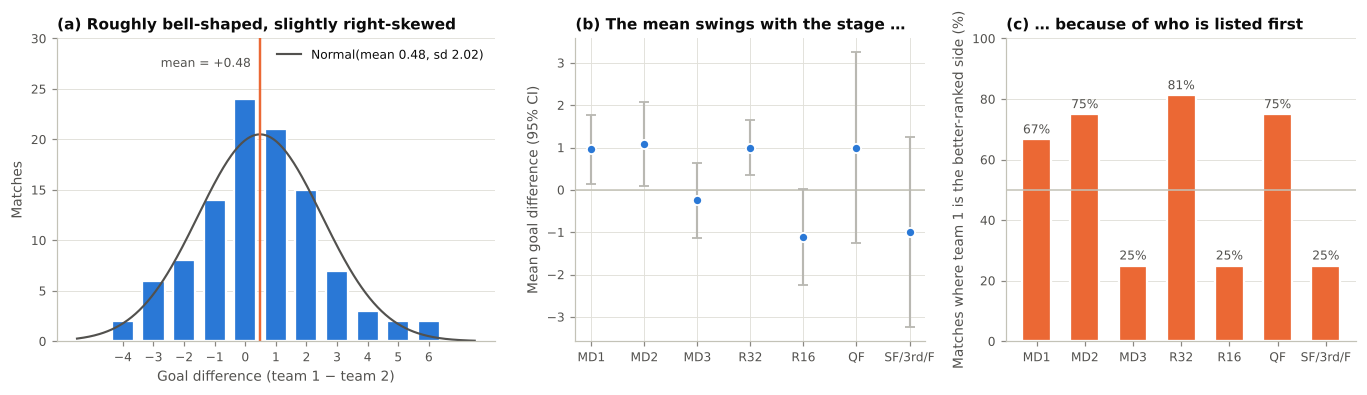

In [4]:
by_stage = df.groupby("stage_ord").agg(
    matches=(TARGET, "size"), mean_gd=(TARGET, "mean"), sd_gd=(TARGET, "std"),
    team1_better_ranked=("log_rank_diff", lambda s: (s > 0).mean()))
by_stage["se"] = by_stage.sd_gd / np.sqrt(by_stage.matches)
by_stage["ci95"] = by_stage.se * stats.t.ppf(0.975, by_stage.matches - 1)
by_stage.index = by_stage.index.map(STAGE_NAME)
display(by_stage)

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6), gridspec_kw={"width_ratios": [1.25, 1, 1]})

ax = axes[0]
vals, counts = np.unique(y, return_counts=True)
ax.bar(vals, counts, width=0.72, color=BLUE, edgecolor="white", linewidth=1.5)
grid_x = np.linspace(-5.5, 7.5, 300)
ax.plot(grid_x, stats.norm.pdf(grid_x, y.mean(), y.std(ddof=1)) * n, color=INK2, lw=1.4,
        label=f"Normal(mean {y.mean():.2f}, sd {y.std(ddof=1):.2f})")
ax.axvline(y.mean(), color=ORANGE, lw=1.6)
ax.annotate(f"mean = +{y.mean():.2f}", (y.mean(), counts.max() + 3.5), xytext=(-6, 0), textcoords="offset points",
            fontsize=8, color=INK2, va="center", ha="right")
ax.set(xlabel="Goal difference (team 1 − team 2)", ylabel="Matches", xticks=range(-4, 7),
       ylim=(0, counts.max() + 6), title="(a) Roughly bell-shaped, slightly right-skewed")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")

ax = axes[1]
xs = np.arange(len(by_stage))
ax.axhline(0, color=AXIS, lw=1)
ax.errorbar(xs, by_stage.mean_gd, yerr=by_stage.ci95, fmt="o", color=BLUE, ecolor=GREY, elinewidth=1.4,
            capsize=3, ms=6, mec="white", mew=1.2)
ax.set_xticks(xs); ax.set_xticklabels(by_stage.index, rotation=0)
ax.set(ylabel="Mean goal difference (95% CI)", title="(b) The mean swings with the stage …")

ax = axes[2]
ax.bar(xs, by_stage.team1_better_ranked * 100, width=0.6, color=ORANGE, edgecolor="white", linewidth=1.5)
ax.axhline(50, color=AXIS, lw=1)
for xi, v in zip(xs, by_stage.team1_better_ranked * 100):
    ax.text(xi, v + 2, f"{v:.0f}%", ha="center", fontsize=8, color=INK2)
ax.set_xticks(xs); ax.set_xticklabels(by_stage.index)
ax.set(ylabel="Matches where team 1 is the better-ranked side (%)", ylim=(0, 100),
       title="(c) … because of who is listed first")
ax.grid(axis="x", visible=False)
fig.tight_layout()
savefig(fig, "fig01_target_distribution_and_orientation")

**Reading the target.**

* Goal difference is an integer between −4 and +6, centred near zero with a standard deviation of about two
  goals. Just under a quarter of the matches were level after extra time. Skewness and excess kurtosis are both small
  (about +0.25). Shapiro–Wilk rejects exact normality, which is expected for a discrete variable; OLS only
  needs approximately normal *residuals*, which we test in Section 12.
* The mean is +0.48 and significantly above zero. Football gives no reason for the *first-named* team to
  win, so this needs an explanation. Panels (b) and (c) give it: the schedule lists the better-ranked
  team first on matchdays 1–2 and in the round of 32 and quarter-finals, and second on matchday 3, the round
  of 16 and the last four matches. The mean goal difference per stage follows that pattern exactly.

This is the first EDA insight that changes the modelling: **the sign of the target depends on an arbitrary
listing convention**, and `stage_ord` is correlated with that convention. Section 5 quantifies the risk.

### 2.2 The eight explanatory variables

,mean,std,min,25%,50%,75%,max,skew,excess_kurt,n_unique,share_zero,IQR_outliers
log_rank_diff,0.382,1.584,-4.143,-0.776,0.431,1.416,4.205,0.069,-0.180,103,0.000,1
log_value_diff,0.349,1.677,-3.683,-0.818,0.508,1.345,4.272,-0.309,-0.126,104,0.000,0
host_home_diff,0.067,0.349,-1.000,0.000,0.000,0.000,1.000,1.036,4.883,3,0.875,13
ppg_diff,0.039,0.493,-1.500,0.000,0.000,0.250,1.200,-0.642,2.110,31,0.481,20
gd_pg_diff,0.104,0.864,-3.000,-0.000,0.000,0.600,1.667,-0.786,1.597,44,0.288,19
rest_days_diff,0.096,0.473,-1.000,0.000,0.000,0.000,2.000,0.867,3.318,4,0.798,21
stage_ord,2.885,1.609,1.000,2.000,3.000,4.000,7.000,0.762,0.023,7,0.000,0
same_confed,0.115,0.321,0.000,0.000,0.000,0.000,1.000,2.443,4.046,2,0.885,12


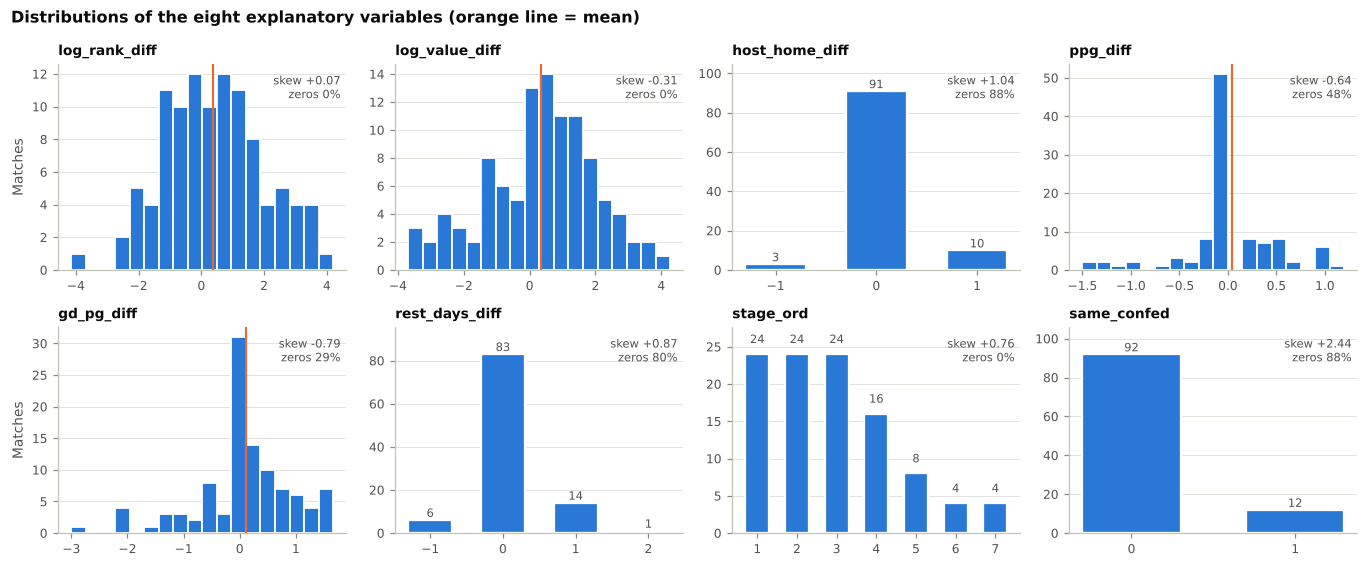

In [5]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); k = 1.5 * (q3 - q1)
    return int(((s < q1 - k) | (s > q3 + k)).sum())

desc_x = df[X8].describe().T
desc_x["skew"] = df[X8].skew()
desc_x["excess_kurt"] = df[X8].kurt()
desc_x["n_unique"] = df[X8].nunique()
desc_x["share_zero"] = (df[X8] == 0).mean()
desc_x["IQR_outliers"] = [iqr_outliers(df[c]) for c in X8]
display(desc_x.drop(columns="count"))

fig, axes = plt.subplots(2, 4, figsize=(12.5, 5.2))
for ax, c in zip(axes.ravel(), X8):
    s = df[c]
    if s.nunique() <= 8:                                   # discrete: one bar per value
        vc = s.value_counts().sort_index()
        ax.bar(vc.index, vc.values, width=0.6, color=BLUE, edgecolor="white", linewidth=1.5)
        ax.set_xticks(vc.index)
        for xi, v in vc.items():
            ax.text(xi, v + 1.5, str(v), ha="center", fontsize=7.5, color=INK2)
        ax.set_ylim(0, vc.max() * 1.15)
    else:
        ax.hist(s, bins=18, color=BLUE, edgecolor="white", linewidth=1.2)
        ax.axvline(s.mean(), color=ORANGE, lw=1.4)
    ax.set_title(c, fontsize=9)
    ax.grid(axis="x", visible=False)
    ax.text(0.98, 0.95, f"skew {s.skew():+.2f}\nzeros {100 * (s == 0).mean():.0f}%", transform=ax.transAxes,
            ha="right", va="top", fontsize=7.5, color=INK2)
for ax in axes[:, 0]:
    ax.set_ylabel("Matches")
fig.suptitle("Distributions of the eight explanatory variables (orange line = mean)", x=0.01, ha="left",
             fontsize=10.5, fontweight="bold")
fig.tight_layout()
savefig(fig, "fig02_feature_distributions")

**Reading the variables.**

* `log_rank_diff` and `log_value_diff` are continuous, symmetric and well spread (sd ≈ 1.6 on the log scale),
  which is the shape a linear model handles best. Their means are slightly positive for the same listing
  reason as the target.
* The form variables are exactly zero in a large share of matches (`ppg_diff` 48 %, `gd_pg_diff` 29 %): all of
  matchday 1 by construction, plus later ties in form. They only start carrying information from matchday 2.
* `host_home_diff`, `rest_days_diff` and `same_confed` are near-constant: 88 %, 80 % and 88 % of matches share
  one value. With so few informative rows (13, 21 and 12 matches) their effects can only be estimated
  imprecisely, whatever the model.
* The IQR rule flags many points in these five variables, but only because their inter-quartile range is
  zero or close to it. The flagged values are legitimate (a host really was at home), so nothing is removed.

### 2.3 Was the log transformation of rank and value the right call?

Role 1 supplied rank and squad value on the log scale. We check that choice against the raw scale, which can
be recovered from the team-level file.

In [6]:
team_info = tm.groupby("team").agg(log_rank=("team_log_rank", "first"), log_value=("team_log_value", "first"))
raw = pd.DataFrame({
    "rank_diff (raw places)": np.exp(team_info.log_rank.reindex(df.team2).to_numpy())
                              - np.exp(team_info.log_rank.reindex(df.team1).to_numpy()),
    "log_rank_diff": df.log_rank_diff,
    "value_diff (raw EUR m)": np.exp(team_info.log_value.reindex(df.team1).to_numpy())
                              - np.exp(team_info.log_value.reindex(df.team2).to_numpy()),
    "log_value_diff": df.log_value_diff,
})
transform_check = pd.DataFrame({
    "Pearson r with goal_diff": [stats.pearsonr(raw[c], y)[0] for c in raw],
    "Spearman rho": [stats.spearmanr(raw[c], y)[0] for c in raw],
    "R2 of simple regression": [stats.pearsonr(raw[c], y)[0] ** 2 for c in raw],
}, index=raw.columns)
display(transform_check)

,Pearson r with goal_diff,Spearman rho,R2 of simple regression
rank_diff (raw places),0.621,0.631,0.386
log_rank_diff,0.629,0.679,0.396
value_diff (raw EUR m),0.574,0.610,0.330
log_value_diff,0.662,0.663,0.438


The log scale is at least as linear as the raw scale for rank and clearly better for squad value
(R² 0.44 against 0.33): a gap of €100 m matters far more between two modest squads than between two
billion-euro squads, and the log captures that diminishing return. The transformation is kept.

## 3. Bivariate and inferential EDA

### 3.1 Each variable against the target

,pearson_r,ci_low,ci_high,p_value,p_holm,spearman_rho,p_spearman,verdict
variable,,,,,,,,
log_rank_diff,0.629,0.496,0.733,0.000,0.000,0.679,0.000,signal
log_value_diff,0.662,0.538,0.758,0.000,0.000,0.663,0.000,signal
host_home_diff,0.160,-0.034,0.342,0.105,0.314,0.154,0.119,no evidence
ppg_diff,0.311,0.126,0.475,0.001,0.007,0.355,0.000,signal
gd_pg_diff,0.327,0.144,0.489,0.001,0.004,0.341,0.000,signal
rest_days_diff,-0.049,-0.239,0.145,0.623,1.000,-0.089,0.367,no evidence
stage_ord,-0.215,-0.392,-0.024,0.028,0.113,-0.196,0.046,no evidence
same_confed,0.033,-0.160,0.224,0.737,1.000,0.042,0.671,no evidence


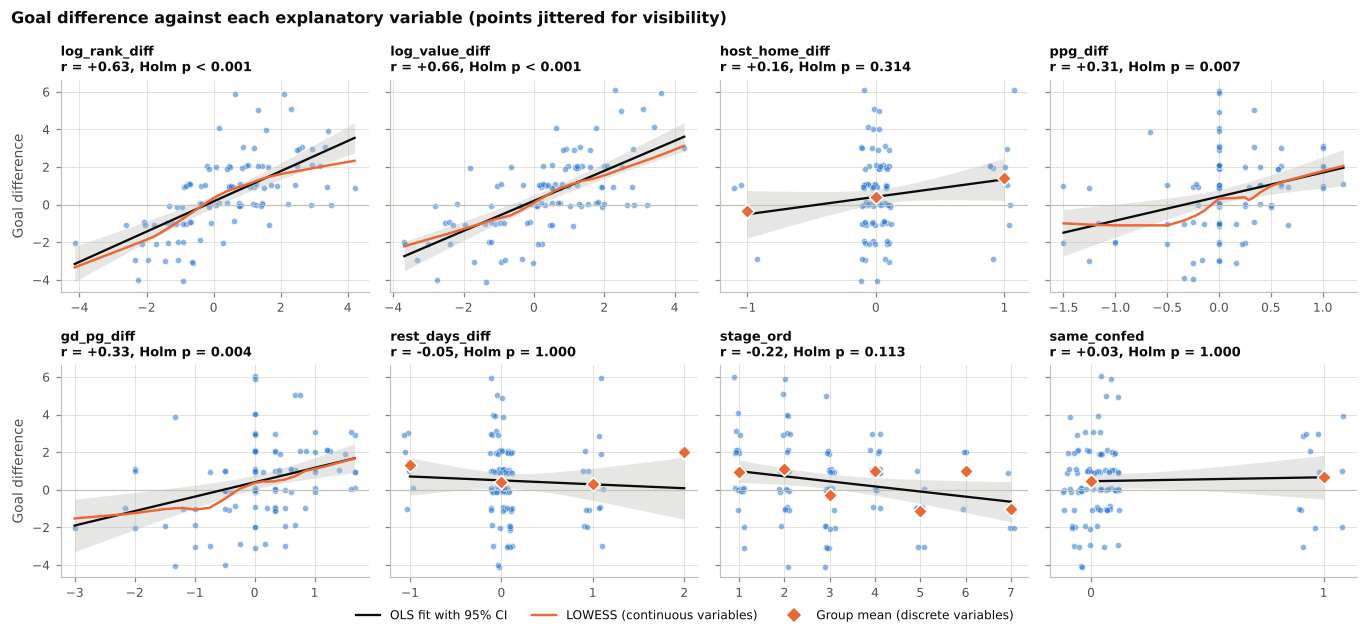

In [7]:
def pearson_ci(r, n_obs, level=0.95):
    z, se = np.arctanh(r), 1 / np.sqrt(n_obs - 3)
    q = stats.norm.ppf(0.5 + level / 2)
    return np.tanh(z - q * se), np.tanh(z + q * se)

rows = []
for c in X8:
    r, p = stats.pearsonr(df[c], y)
    lo, hi = pearson_ci(r, n)
    rho, p_s = stats.spearmanr(df[c], y)
    rows.append(dict(variable=c, pearson_r=r, ci_low=lo, ci_high=hi, p_value=p, spearman_rho=rho, p_spearman=p_s))
corr_tab = pd.DataFrame(rows).set_index("variable")
corr_tab["p_holm"] = multipletests(corr_tab.p_value, method="holm")[1]
corr_tab["verdict"] = np.where(corr_tab.p_holm < 0.05, "signal", "no evidence")
display(corr_tab[["pearson_r", "ci_low", "ci_high", "p_value", "p_holm", "spearman_rho", "p_spearman", "verdict"]])

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 4, figsize=(12.5, 5.6), sharey=True)
for ax, c in zip(axes.ravel(), X8):
    x = df[c].to_numpy(float)
    discrete = df[c].nunique() <= 8
    xj = x + (rng.uniform(-0.12, 0.12, n) if discrete else 0)
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.scatter(xj, y + rng.uniform(-0.12, 0.12, n), s=16, color=BLUE, alpha=0.55, edgecolor="white", linewidth=0.5)
    fit = sm.OLS(y, sm.add_constant(x)).fit()
    gx = np.linspace(x.min(), x.max(), 100)
    pred = fit.get_prediction(sm.add_constant(gx)).summary_frame()
    ax.fill_between(gx, pred.mean_ci_lower, pred.mean_ci_upper, color=GREY, alpha=0.35, lw=0)
    ax.plot(gx, pred["mean"], color=INK, lw=1.5)
    if discrete:                                           # group means
        gm = df.groupby(c)[TARGET].mean()
        ax.scatter(gm.index, gm.values, marker="D", s=42, color=ORANGE, edgecolor="white", linewidth=1, zorder=5)
        ax.set_xticks(sorted(df[c].unique()))
    else:                                                  # LOWESS as a linearity check
        lo_fit = lowess(y, x, frac=0.7)
        ax.plot(lo_fit[:, 0], lo_fit[:, 1], color=ORANGE, lw=1.6)
    r, p = corr_tab.loc[c, ["pearson_r", "p_holm"]]
    ax.set_title(f"{c}\nr = {r:+.2f}, Holm p = {p:.3f}" if p >= 0.001 else f"{c}\nr = {r:+.2f}, Holm p < 0.001",
                 fontsize=8.5)
for ax in axes[:, 0]:
    ax.set_ylabel("Goal difference")
fig.legend(handles=[Line2D([], [], color=INK, lw=1.5, label="OLS fit with 95% CI"),
                    Line2D([], [], color=ORANGE, lw=1.6, label="LOWESS (continuous variables)"),
                    Line2D([], [], color=ORANGE, marker="D", lw=0, label="Group mean (discrete variables)")],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.03))
fig.suptitle("Goal difference against each explanatory variable (points jittered for visibility)", x=0.01,
             ha="left", fontsize=10.5, fontweight="bold")
fig.tight_layout()
savefig(fig, "fig03_bivariate_scatter")

**What the scatter plots show.**

* The two strength variables dominate (r ≈ 0.63 and 0.66). Their LOWESS curves follow the straight OLS line
  and stay inside or at the edge of its confidence band, so a **linear** specification is appropriate. The
  rank curve flattens slightly for the most one-sided matches; whether that deserves a curvature term is
  tested in Section 8 (cubic term) and Section 12 (RESET test).
* The two form variables have moderate raw correlations (r ≈ 0.31–0.33) that survive the Holm correction.
  Section 4 tests whether this is information beyond team strength.
* `host_home_diff` points in the expected direction (hosts at home average +1.4 goals) but with only 13
  informative matches the raw correlation is not significant.
* `rest_days_diff` and `same_confed` show nothing. `stage_ord` has a negative raw correlation (p = 0.028
  before correction), the listing pattern already seen in Section 2.1.

### 3.2 Group comparisons for the discrete variables

For the two variables that do not change sign when teams are swapped, a signed target is the wrong place to
look. Their hypotheses ("later rounds are tighter", "familiar opponents play closer games") are statements
about the **size** of the margin, so we also test the absolute goal difference.

In [8]:
abs_y = np.abs(y)
is_host1 = df.host_home_diff == 1
ko = (df.stage_ord >= 4).to_numpy()
tests = []

t = stats.ttest_ind(y[is_host1], y[df.host_home_diff == 0], equal_var=False)
tests.append(("Host at home as team 1 vs neutral: signed GD (Welch t)", y[is_host1].mean(), y[df.host_home_diff == 0].mean(), t.pvalue))
f = stats.f_oneway(*[g[TARGET].to_numpy() for _, g in df.groupby("host_home_diff")])
tests.append(("host_home_diff -1/0/+1: signed GD (one-way ANOVA)", np.nan, np.nan, f.pvalue))
k = stats.kruskal(*[g[TARGET].to_numpy() for _, g in df.groupby("stage_ord")])
tests.append(("stage_ord (7 levels): signed GD (Kruskal-Wallis)", np.nan, np.nan, k.pvalue))
t = stats.ttest_ind(y[df.same_confed == 1], y[df.same_confed == 0], equal_var=False)
tests.append(("Same confederation vs not: signed GD (Welch t)", y[df.same_confed == 1].mean(), y[df.same_confed == 0].mean(), t.pvalue))
u = stats.mannwhitneyu(abs_y[df.same_confed == 1], abs_y[df.same_confed == 0])
tests.append(("Same confederation vs not: |GD| (Mann-Whitney)", abs_y[df.same_confed == 1].mean(), abs_y[df.same_confed == 0].mean(), u.pvalue))
u = stats.mannwhitneyu(abs_y[ko], abs_y[~ko])
tests.append(("Knockout vs group stage: |GD| (Mann-Whitney)", abs_y[ko].mean(), abs_y[~ko].mean(), u.pvalue))
lv = stats.levene(y[ko], y[~ko])
tests.append(("Knockout vs group stage: variance of GD (Levene)", y[ko].std(ddof=1), y[~ko].std(ddof=1), lv.pvalue))
sp = stats.spearmanr(df.stage_ord, abs_y)
tests.append(("stage_ord vs |GD| (Spearman rho = %.2f)" % sp[0], np.nan, np.nan, sp[1]))
group_tests = pd.DataFrame(tests, columns=["test", "group A (mean / sd)", "group B (mean / sd)", "p_value"]).set_index("test")
group_tests["p_holm"] = multipletests(group_tests.p_value, method="holm")[1]
with pd.option_context("display.max_colwidth", 70):
    display(group_tests)
same = df[df.same_confed == 1]
print(f"same_confed = 1 in {len(same)} matches; teams involved: {sorted(set(same.team1) | set(same.team2))}")

,group A (mean / sd),group B (mean / sd),p_value,p_holm
test,,,,
Host at home as team 1 vs neutral: signed GD (Welch t),1.400,0.407,0.236,1.000
host_home_diff -1/0/+1: signed GD (one-way ANOVA),NaN,NaN,0.265,1.000
stage_ord (7 levels): signed GD (Kruskal-Wallis),NaN,NaN,0.012,0.093
Same confederation vs not: signed GD (Welch t),0.667,0.457,0.775,1.000
Same confederation vs not: |GD| (Mann-Whitney),2.167,1.478,0.032,0.221
Knockout vs group stage: |GD| (Mann-Whitney),1.344,1.653,0.649,1.000
Knockout vs group stage: variance of GD (Levene),1.601,2.186,0.292,1.000
stage_ord vs |GD| (Spearman rho = 0.00),NaN,NaN,0.963,1.000


same_confed = 1 in 12 matches; teams involved: ['Austria', 'Belgium', 'Bosnia & Herzegovina', 'Croatia', 'England', 'France', 'Netherlands', 'Norway', 'Portugal', 'Spain', 'Sweden', 'Switzerland']


**Reading the tests.**

* Two raw p-values fall below 0.05, and neither survives the Holm correction for the eight tests.
* The first is the difference in *signed* goal difference across stages (Kruskal–Wallis p = 0.012). Section
  2.1 already showed where it comes from: the listing order. Section 5 tests that explanation directly.
* Neither hypothesis about the *size* of the margin is supported. Knockout matches were not significantly
  tighter than group matches (mean |GD| 1.34 against 1.65, p = 0.65; Levene p = 0.29) and stage has no
  monotonic relationship with |GD| (ρ = 0.00).
* The second is `same_confed`: those matches had *larger* margins (2.17 against 1.48 goals, raw p = 0.03),
  the opposite of the hypothesis. All 12 such matches are between two European teams, so in this tournament
  the variable is really a "Europe v Europe" flag. With 12 matches this is weak evidence, but it explains why
  an interaction with `same_confed` looks tempting in Section 8 and why it is treated with caution there.

The two sign-invariant variables therefore show no reliable effect on the direction or on the size of the
result.

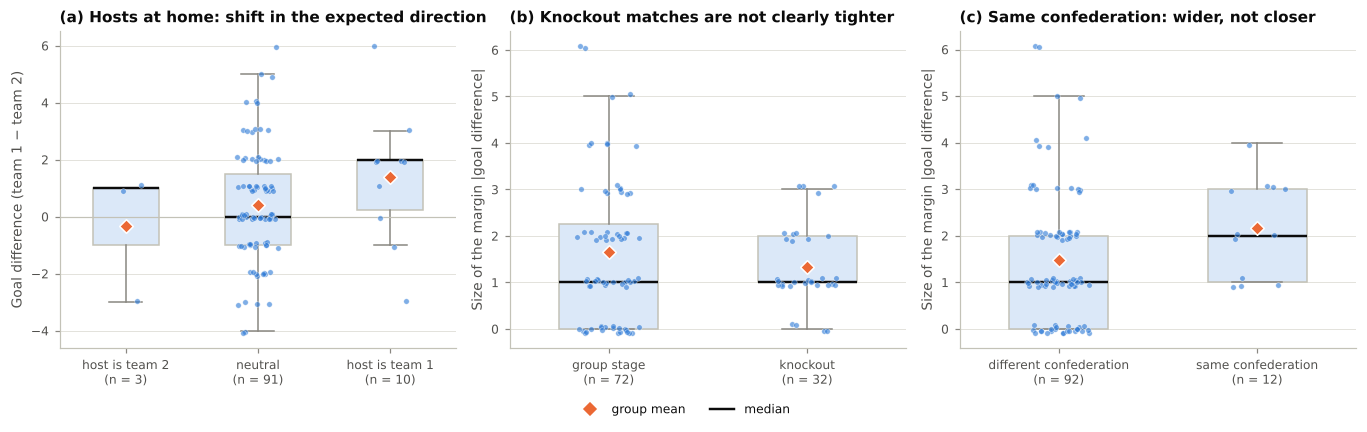

In [9]:
def box_with_points(ax, groups, labels, colour=BLUE):
    """Box plot with the individual matches overlaid (jittered)."""
    bp = ax.boxplot(groups, widths=0.5, patch_artist=True, showfliers=False,
                    medianprops=dict(color=INK, lw=1.6), boxprops=dict(facecolor="#dbe8f8", edgecolor=AXIS),
                    whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
    jit = np.random.default_rng(SEED)
    for i, g in enumerate(groups, start=1):
        ax.scatter(i + jit.uniform(-0.16, 0.16, len(g)), np.asarray(g) + jit.uniform(-0.1, 0.1, len(g)), s=13,
                   color=colour, alpha=0.6, edgecolor="white", linewidth=0.4, zorder=3)
        ax.scatter(i, np.mean(g), marker="D", s=40, color=ORANGE, edgecolor="white", linewidth=1, zorder=4)
    ax.set_xticks(range(1, len(groups) + 1)); ax.set_xticklabels(labels)
    ax.grid(axis="x", visible=False)

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.7))
box_with_points(axes[0], [y[df.host_home_diff == v] for v in (-1, 0, 1)],
                ["host is team 2\n(n = 3)", "neutral\n(n = 91)", "host is team 1\n(n = 10)"])
axes[0].axhline(0, color=AXIS, lw=0.8)
axes[0].set(ylabel="Goal difference (team 1 − team 2)", title="(a) Hosts at home: shift in the expected direction")
box_with_points(axes[1], [abs_y[~ko], abs_y[ko]], ["group stage\n(n = 72)", "knockout\n(n = 32)"])
axes[1].set(ylabel="Size of the margin |goal difference|", title="(b) Knockout matches are not clearly tighter")
box_with_points(axes[2], [abs_y[df.same_confed == 0], abs_y[df.same_confed == 1]],
                ["different confederation\n(n = 92)", "same confederation\n(n = 12)"])
axes[2].set(ylabel="Size of the margin |goal difference|", title="(c) Same confederation: wider, not closer")
fig.legend(handles=[Line2D([], [], marker="D", color=ORANGE, lw=0, label="group mean"),
                    Line2D([], [], color=INK, lw=1.6, label="median")], loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.06))
fig.tight_layout()
savefig(fig, "fig03b_group_boxplots")

### 3.3 A categorical view: does the better-ranked team win?

Treating the result as a category (team 1 wins / level / team 2 wins) gives a check on the strength signal
that does not depend on the linear model or on the size of the margin.

In [10]:
favourite = pd.Series(np.where(df.log_rank_diff > 0, "team 1 better ranked", "team 2 better ranked"), name="before the match")
result = pd.Series(np.select([y > 0, y < 0], ["team 1 wins", "team 2 wins"], "level"), name="result")
ct = pd.crosstab(favourite, result)[["team 1 wins", "level", "team 2 wins"]]
chi2, p_chi, dof, expected = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
display(ct)
display(pd.crosstab(favourite, result, normalize="index")[["team 1 wins", "level", "team 2 wins"]].round(2))
print(f"Chi-square test of independence: chi2({dof}) = {chi2:.1f}, p = {p_chi:.1e}; Cramér's V = {cramers_v:.2f}; "
      f"smallest expected count = {expected.min():.1f}")
n_decisive = int((y != 0).sum())
fav_won = int(((np.sign(df.log_rank_diff.to_numpy()) == np.sign(y)) & (y != 0)).sum())
bt = stats.binomtest(fav_won, n_decisive, 0.5)
ci_fav = bt.proportion_ci(method="wilson")
print(f"The better-ranked team won {fav_won} of the {n_decisive} decisive matches ({fav_won / n_decisive:.0%}; "
      f"95% Wilson CI {ci_fav.low:.0%}–{ci_fav.high:.0%}); binomial test against 50%: p = {bt.pvalue:.1e}")

result,team 1 wins,level,team 2 wins
before the match,,,
team 1 better ranked,41,15,3
team 2 better ranked,9,9,27


result,team 1 wins,level,team 2 wins
before the match,,,
team 1 better ranked,0.690,0.250,0.050
team 2 better ranked,0.200,0.200,0.600


Chi-square test of independence: chi2(2) = 40.0, p = 2.0e-09; Cramér's V = 0.62; smallest expected count = 10.4
The better-ranked team won 68 of the 80 decisive matches (85%; 95% Wilson CI 76%–91%); binomial test against 50%: p = 1.2e-10


**Reading.** Result and pre-match ranking are strongly associated (χ²(2) = 40.0, p < 0.001, Cramér's V = 0.62;
all expected counts are above 5, so the test is valid). When team 1 is the better-ranked side it wins 69 % of the
time and loses 5 %; when team 2 is better ranked, team 1 wins only 20 %. Across the 80 decisive matches the
better-ranked team won 68 (85 %, 95 % CI 76–91 %). The box plots show the three group comparisons tested in
Section 3.2. Strength is the dominant signal whichever way the outcome is measured; the regression's job is to
turn it into an expected margin.

## 4. Redundancy among the explanatory variables

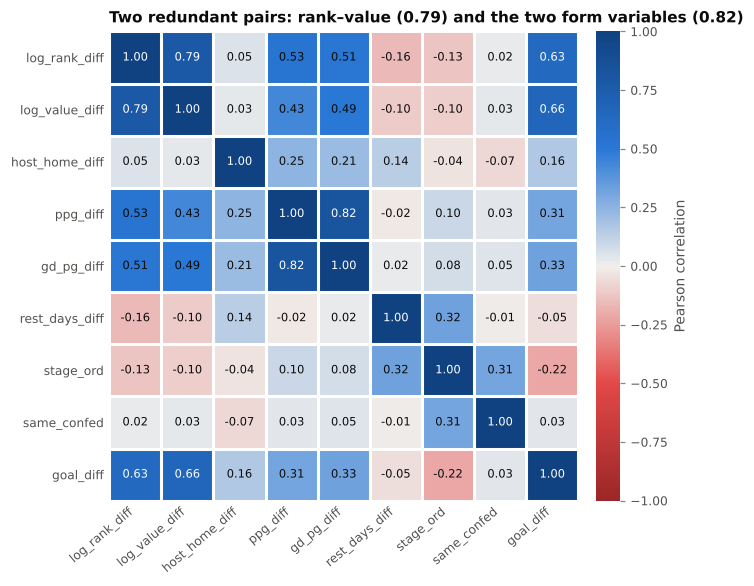

,log_rank_diff,log_value_diff,host_home_diff,ppg_diff,gd_pg_diff,rest_days_diff,stage_ord,same_confed
VIF,3.078,2.771,1.118,3.421,3.323,1.188,1.324,1.129


Condition number of the standardised design matrix: 4.3


In [11]:
corr = df[X8 + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(6.6, 5.4))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=40, ha="right"); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(v) > 0.55 else INK)
ax.set_xticks(np.arange(-0.5, len(corr)), minor=True); ax.set_yticks(np.arange(-0.5, len(corr)), minor=True)
ax.grid(which="minor", color="white", linewidth=2); ax.grid(which="major", visible=False)
ax.tick_params(which="both", length=0)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03); cb.outline.set_visible(False)
cb.set_label("Pearson correlation")
ax.set_title("Two redundant pairs: rank–value (0.79) and the two form variables (0.82)")
fig.tight_layout()
savefig(fig, "fig04_correlation_heatmap")

Xc8 = sm.add_constant(df[X8])
vif = pd.Series([variance_inflation_factor(Xc8.to_numpy(), i + 1) for i in range(len(X8))], index=X8, name="VIF")
display(vif.to_frame().T)
print(f"Condition number of the standardised design matrix: {np.linalg.cond(StandardScaler().fit_transform(df[X8])):.1f}")

In [12]:
df["strength"] = (df.log_rank_diff + df.log_value_diff) / 2      # parameter-free composite (see Section 8)

def partial_corr(a, b, control):
    """Correlation between a and b after removing the linear effect of `control` from both."""
    C = sm.add_constant(np.asarray(control, float))
    ra = sm.OLS(np.asarray(a, float), C).fit().resid
    rb = sm.OLS(np.asarray(b, float), C).fit().resid
    r, _ = stats.pearsonr(ra, rb)
    dof = len(ra) - 3                                             # one control variable
    tval = r * np.sqrt(dof / (1 - r ** 2))
    return r, 2 * stats.t.sf(abs(tval), dof)

pc_rows = []
for c in ["ppg_diff", "gd_pg_diff", "host_home_diff", "rest_days_diff"]:
    r0, p0 = stats.pearsonr(df[c], y)
    r1, p1 = partial_corr(df[c], y, df.strength)
    pc_rows.append(dict(variable=c, raw_r=r0, raw_p=p0, partial_r_given_strength=r1, partial_p=p1,
                        r_with_strength=stats.pearsonr(df[c], df.strength)[0]))
display(pd.DataFrame(pc_rows).set_index("variable"))

,raw_r,raw_p,partial_r_given_strength,partial_p,r_with_strength
variable,,,,,
ppg_diff,0.311,0.001,-0.056,0.577,0.507
gd_pg_diff,0.327,0.001,-0.058,0.561,0.531
host_home_diff,0.160,0.105,0.181,0.067,0.041
rest_days_diff,-0.049,0.623,0.064,0.519,-0.139


**Redundancy findings.**

* VIFs are all below 3.5, so there is no severe multicollinearity, but two pairs are clearly measuring the
  same thing: FIFA rank and squad value (r = 0.79), and the two form variables (r = 0.82). Splitting one
  signal across two correlated coefficients inflates their standard errors without adding information.
* **In-tournament form is strength in disguise.** `ppg_diff` and `gd_pg_diff` correlate about 0.5 with team
  strength, and once strength is held constant their partial correlation with the target drops to about
  −0.06 (p > 0.5). After at most six matches, "form" mostly records that strong teams have been winning.
  It is not an independent predictor.
* `host_home_diff` is the only secondary variable whose association *strengthens* when strength is
  controlled (partial r = +0.18, p ≈ 0.07), because hosts are not unusually strong teams.

These findings set up the feature engineering in Section 8: merge the redundant strength pair into one
index, and expect the form variables to drop out.

## 5. The orientation problem: is a "significant" effect just the listing order?

Which team is called *team 1* is a scheduling convention. If we swapped the two names in any match, the
goal difference and the six difference-type variables would all flip sign, but nothing about the football
would change. A sound model should therefore give the mirrored prediction for the mirrored match. That has
two consequences for a linear model:

1. the **intercept must be zero** (two identical teams have an expected goal difference of zero), and
2. variables that do not flip sign (`stage_ord`, `same_confed`) **cannot have a main effect** on a signed
   goal difference; at most they can change how strongly the other variables act.

The full 8-variable OLS ignores both points. To see whether that matters, we run a **random relabelling
test**: swap team 1 and team 2 in a random half of the matches (flipping the sign of the target and of the
six odd variables), refit, and repeat 2,000 times. A real football effect should survive relabelling; an
artefact of the listing order should vanish.

In [13]:
ODD = X8[:6]                      # flip sign when the teams are swapped
EVEN = X8[6:]                     # unchanged when the teams are swapped
ols8 = sm.OLS(y, Xc8).fit()

rng = np.random.default_rng(SEED)
B_FLIP = 2000
coef_flip = np.empty((B_FLIP, len(X8) + 1)); p_flip = np.empty_like(coef_flip)
X_flip = Xc8.copy()
for b in range(B_FLIP):
    sgn = rng.choice([-1.0, 1.0], size=n)
    X_flip[ODD] = df[ODD].to_numpy() * sgn[:, None]
    fit_b = sm.OLS(y * sgn, X_flip).fit()
    coef_flip[b], p_flip[b] = fit_b.params.to_numpy(), fit_b.pvalues.to_numpy()

flip_tab = pd.DataFrame({
    "coef_as_scheduled": ols8.params, "p_as_scheduled": ols8.pvalues,
    "mean_coef_relabelled": coef_flip.mean(0), "sd_coef_relabelled": coef_flip.std(0),
    "share_significant_relabelled": (p_flip < 0.05).mean(0),
})
flip_tab.index = ["intercept"] + X8
display(flip_tab)

# Mirror check: rename team 1 <-> team 2 in every match. A consistent model must return exactly minus its prediction.
mirror = df[X8].copy()
mirror[ODD] = -mirror[ODD]
gap_full = np.abs(ols8.predict(Xc8) + ols8.predict(sm.add_constant(mirror, has_constant="add")))
print(f"Full OLS: prediction + mirrored prediction = {gap_full.mean():.2f} goals on average (max {gap_full.max():.2f}); "
      f"a symmetric model gives exactly 0 by construction")

,coef_as_scheduled,p_as_scheduled,mean_coef_relabelled,sd_coef_relabelled,share_significant_relabelled
intercept,0.653,0.046,0.002,0.331,0.070
log_rank_diff,0.372,0.022,0.413,0.031,0.992
log_value_diff,0.543,0.000,0.555,0.023,1.000
host_home_diff,0.779,0.078,0.907,0.063,0.783
ppg_diff,-0.025,0.963,-0.206,0.082,0.000
gd_pg_diff,-0.137,0.655,-0.122,0.046,0.000
rest_days_diff,0.360,0.282,0.190,0.067,0.000
stage_ord,-0.220,0.035,0.001,0.101,0.056
same_confed,0.515,0.283,-0.002,0.523,0.068


Full OLS: prediction + mirrored prediction = 0.56 goals on average (max 1.90); a symmetric model gives exactly 0 by construction


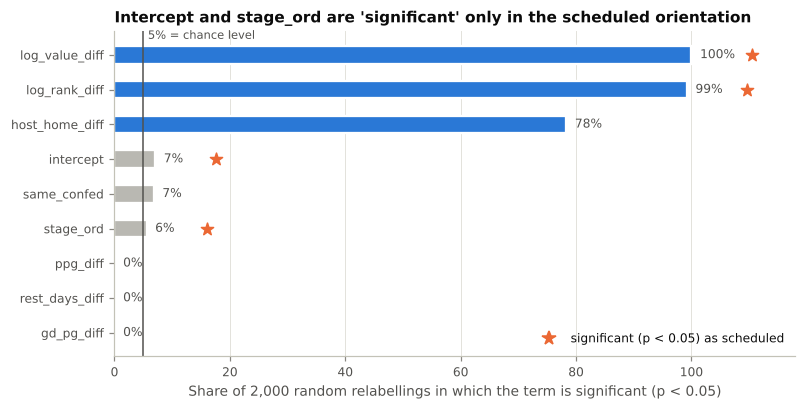

In [14]:
order = flip_tab.sort_values("share_significant_relabelled").index
fig, ax = plt.subplots(figsize=(7.4, 3.8))
ypos = np.arange(len(order))
share = flip_tab.loc[order, "share_significant_relabelled"] * 100
sig_now = flip_tab.loc[order, "p_as_scheduled"] < 0.05
ax.barh(ypos, share, height=0.5, color=np.where(share > 50, BLUE, GREY), edgecolor="white", linewidth=1.5)
ax.axvline(5, color=INK2, lw=1)
ax.text(5.8, len(order) - 0.45, "5% = chance level", fontsize=7.5, color=INK2, va="center")
for yi, (v, s) in enumerate(zip(share, sig_now)):
    ax.text(v + 1.5, yi, f"{v:.0f}%", va="center", fontsize=8, color=INK2)
    if s:
        ax.scatter(v + 10.5, yi, marker="*", s=70, color=ORANGE, zorder=5)
ax.set_yticks(ypos); ax.set_yticklabels(order)
ax.set(xlim=(0, 118), xticks=range(0, 101, 20), xlabel="Share of 2,000 random relabellings in which the term is significant (p < 0.05)",
       title="Intercept and stage_ord are 'significant' only in the scheduled orientation")
ax.legend(handles=[Line2D([], [], marker="*", color=ORANGE, lw=0, ms=9, label="significant (p < 0.05) as scheduled")],
          loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
savefig(fig, "fig05_relabelling_test")

**Result.** In the scheduled orientation the full OLS reports four "significant" terms: both strength
variables, the intercept (p = 0.046) and `stage_ord` (p = 0.035). Under random relabelling:

* the strength variables stay significant in 99–100 % of relabellings, and `host_home_diff` in about three
  quarters of them: these are properties of the football;
* the intercept and `stage_ord` are significant in only 6–7 % of relabellings, which is the 5 % false-positive
  rate one expects from pure noise. Their mean coefficients collapse to zero.

So the apparent stage effect is produced by the listing order, not by the tournament. A model that keeps it
will look better in-sample and then fail on any match whose orientation differs from the pattern it learned.
The mirror check makes the same point in goals: swapping the names in every match changes the full OLS
prediction by 0.56 goals on average (up to 1.90) instead of simply flipping its sign.

This motivates the **symmetric specification** used from Section 8 onward: no intercept, and only
sign-flipping variables as main effects. Section 10 confirms the practical cost of ignoring this.

## 6. Validation protocol

With 104 matches a single train/test split would be dominated by luck, so every model is scored with the
same three complementary schemes:

| Scheme | What it does | Why |
|---|---|---|
| **Repeated 10-fold CV** (30 repeats, identical folds for every model) | 300 train/test fits; out-of-fold predictions are pooled within each repeat | Stable estimate of error on unseen matches; the spread across repeats shows how much is luck of the split |
| **Walk-forward by stage** | Train on all earlier stages, predict the next one (MD2 → … → final), 80 forecasts | Mimics real use: forecasting upcoming matches from past ones, never the reverse |
| **Leave-one-out** (final model only) | 104 fits, each predicting one held-out match | Used for per-match residuals and prediction-interval coverage |

Metrics: **RMSE** (goals, penalises big misses), **MAE** (goals, typical miss) and out-of-sample **R²**
(1 − SSE / SST, with SST measured around the overall mean). Hyper-parameters of regularised models are tuned
*inside* each training fold (nested CV), so no model ever sees its test matches.

In [15]:
N_SPLITS, N_REPEATS = 10, 30
SPLITS = list(RepeatedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED).split(df))
SST = ((y - y.mean()) ** 2).sum()
INNER = KFold(n_splits=5, shuffle=True, random_state=SEED)      # inner folds for hyper-parameter tuning
WF_STAGES = range(2, 8)
wf_mask = (df.stage_ord >= 2).to_numpy()                        # the 80 matches that can be forecast


def repeated_cv(est, cols, target=y, back=None):
    """Repeated k-fold CV with shared folds. Returns per-repeat metrics and fold-level MSE."""
    X = df[cols].to_numpy(float)
    rmse, mae, r2, fold_mse = [], [], [], []
    for rep in range(N_REPEATS):
        pred = np.empty(n)
        for tr, te in SPLITS[rep * N_SPLITS:(rep + 1) * N_SPLITS]:
            p = clone(est).fit(X[tr], target[tr]).predict(X[te])
            pred[te] = back(p) if back else p
            fold_mse.append(((y[te] - pred[te]) ** 2).mean())
        err = y - pred
        rmse.append(np.sqrt((err ** 2).mean())); mae.append(np.abs(err).mean()); r2.append(1 - (err ** 2).sum() / SST)
    return dict(rmse=np.array(rmse), mae=np.array(mae), r2=np.array(r2), fold_mse=np.array(fold_mse))


def walk_forward(est, cols, target=y, back=None):
    """Train on all earlier stages, predict the next stage. Returns predictions (NaN for matchday 1)."""
    X = df[cols].to_numpy(float)
    pred = np.full(n, np.nan)
    for s in WF_STAGES:
        tr, te = (df.stage_ord < s).to_numpy(), (df.stage_ord == s).to_numpy()
        p = clone(est).fit(X[tr], target[tr]).predict(X[te])
        pred[te] = back(p) if back else p
    return pred


def score(name, est, cols, family="", **kw):
    """Run both schemes for one model and return a one-row summary (details kept in STORE)."""
    cv = repeated_cv(est, cols, **kw)
    wf = walk_forward(est, cols, **kw)
    e = (y - wf)[wf_mask]
    STORE[name] = dict(cv=cv, wf=wf, est=est, cols=cols)
    return dict(model=name, family=family, n_terms=0 if family == "baseline" else len(cols),
                cv_rmse=cv["rmse"].mean(), cv_rmse_sd=cv["rmse"].std(ddof=1), cv_mae=cv["mae"].mean(),
                cv_r2=cv["r2"].mean(), wf_rmse=np.sqrt((e ** 2).mean()), wf_mae=np.abs(e).mean())


def corrected_ttest(a, b):
    """Nadeau-Bengio corrected resampled t-test on fold-level MSE (a minus b)."""
    d = STORE[a]["cv"]["fold_mse"] - STORE[b]["cv"]["fold_mse"]
    k = len(d)
    t_stat = d.mean() / np.sqrt((1 / k + 1 / (N_SPLITS - 1)) * d.var(ddof=1))
    return d.mean(), t_stat, 2 * stats.t.sf(abs(t_stat), k - 1)


STORE = {}
OLS = LinearRegression()
OLS0 = LinearRegression(fit_intercept=False)                    # symmetric specification: no intercept
# Full 8-variable OLS on standardised predictors. Predictions are identical to plain OLS whenever the design
# has full rank. In the first walk-forward window (matchday 1 only) four variables are constant; scaling sets
# them to zero so their unidentifiable coefficients are estimated as zero instead of an arbitrary value.
OLS_STD = make_pipeline(StandardScaler(), LinearRegression())

## 7. Baselines and the full 8-variable OLS

Two naive baselines give the scale of the problem: always predicting the training mean, and always
predicting a draw. A one-variable regression on FIFA rank shows what the single most obvious predictor
achieves. The full OLS uses all eight variables exactly as supplied and is our reference model.

In [16]:
base_rows = [
    score("Baseline: training mean", DummyRegressor(strategy="mean"), X8, "baseline"),
    score("Baseline: always a draw", DummyRegressor(strategy="constant", constant=0.0), X8, "baseline"),
    score("Simple OLS: log_rank_diff", OLS, ["log_rank_diff"], "OLS"),
    score("Full OLS: all 8 variables", OLS_STD, X8, "OLS"),
]
base_tab = pd.DataFrame(base_rows).set_index("model")
display(base_tab.drop(columns="family"))
print(ols8.summary())

,n_terms,cv_rmse,cv_rmse_sd,cv_mae,cv_r2,wf_rmse,wf_mae
model,,,,,,,
Baseline: training mean,0,2.033,0.008,1.591,-0.019,2.101,1.649
Baseline: always a draw,0,2.071,0.000,1.558,-0.057,2.059,1.587
Simple OLS: log_rank_diff,1,1.599,0.010,1.235,0.370,1.553,1.200
Full OLS: all 8 variables,8,1.546,0.024,1.226,0.411,1.817,1.418


                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.517
Model:                            OLS   Adj. R-squared:                  0.477
Method:                 Least Squares   F-statistic:                     12.72
Date:                Thu, 08 Oct 2026   Prob (F-statistic):           2.81e-12
Time:                        17:33:10   Log-Likelihood:                -182.53
No. Observations:                 104   AIC:                             383.1
Df Residuals:                      95   BIC:                             406.9
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              0.6531      0.322      2.

In [17]:
std8 = sm.OLS(stats.zscore(y, ddof=1), sm.add_constant(df[X8].apply(stats.zscore, ddof=1))).fit()
full_tab = pd.DataFrame({"coef": ols8.params, "std_err": ols8.bse, "t": ols8.tvalues, "p": ols8.pvalues,
                         "ci_low": ols8.conf_int()[0], "ci_high": ols8.conf_int()[1],
                         "standardised_beta": std8.params, "VIF": vif}).reindex(["const"] + X8)
display(full_tab)
print(f"In-sample R2 = {ols8.rsquared:.3f}, adjusted R2 = {ols8.rsquared_adj:.3f}, "
      f"F = {ols8.fvalue:.2f} (p = {ols8.f_pvalue:.1e}), AIC = {ols8.aic:.1f}, BIC = {ols8.bic:.1f}")
print(f"Out-of-sample: CV R2 = {base_tab.loc['Full OLS: all 8 variables', 'cv_r2']:.3f}, "
      f"CV RMSE = {base_tab.loc['Full OLS: all 8 variables', 'cv_rmse']:.3f}, "
      f"walk-forward RMSE = {base_tab.loc['Full OLS: all 8 variables', 'wf_rmse']:.3f}")

,coef,std_err,t,p,ci_low,ci_high,standardised_beta,VIF
const,0.653,0.322,2.026,0.046,0.013,1.293,-0.000,NaN
log_rank_diff,0.372,0.160,2.328,0.022,0.055,0.689,0.291,3.078
log_value_diff,0.543,0.143,3.787,0.000,0.258,0.827,0.449,2.771
host_home_diff,0.779,0.437,1.782,0.078,-0.089,1.648,0.134,1.118
ppg_diff,-0.025,0.542,-0.047,0.963,-1.101,1.050,-0.006,3.421
gd_pg_diff,-0.137,0.304,-0.449,0.655,-0.741,0.468,-0.058,3.323
rest_days_diff,0.360,0.332,1.082,0.282,-0.300,1.020,0.084,1.188
stage_ord,-0.220,0.103,-2.134,0.035,-0.425,-0.015,-0.175,1.324
same_confed,0.515,0.477,1.079,0.283,-0.433,1.463,0.082,1.129


In-sample R2 = 0.517, adjusted R2 = 0.477, F = 12.72 (p = 2.8e-12), AIC = 383.1, BIC = 406.9
Out-of-sample: CV R2 = 0.411, CV RMSE = 1.546, walk-forward RMSE = 1.817


**Reading the reference model.**

* The full OLS is highly significant overall (F-test p < 0.001) and explains 52 % of the in-sample variance
  (adjusted 48 %). Out of sample, though, R² falls to about 0.41: a fifth of the apparent fit is optimism.
* Only the two strength variables are solidly significant. The form variables have the wrong sign and
  p > 0.6, as the partial correlations predicted. `rest_days_diff` and `same_confed` are not significant.
  The intercept and `stage_ord` are nominally significant, but Section 5 showed that both are orientation
  artefacts.
* The warning sign is the walk-forward result. When the model has to forecast later rounds from earlier
  ones, the full OLS scores an RMSE of about 1.82, **worse than the one-variable rank model (1.55)**.
  Random CV hides this because every fold contains matches from every stage, so the listing pattern learned
  in training is also present in the test fold.

The full model therefore overfits in a specific, diagnosable way. The next section fixes it.

## 8. Feature engineering experiments driven by the EDA

Each experiment below tests one idea that came out of Sections 3–5. All engineered terms are deterministic
functions of the eight supplied columns; no new data is introduced, so the dataset still contains exactly
eight explanatory variables.

| Idea from EDA | Engineered change |
|---|---|
| Rank and value are redundant (r = 0.79) | **Strength index** = mean of `log_rank_diff` and `log_value_diff` |
| Orientation artefact (§5) | **Symmetric model**: drop the intercept, use only sign-flipping main effects |
| Even variables can only moderate | Interactions `strength × knockout`, `strength × same_confed` |
| Is the effect of strength linear? | Odd polynomial term `strength³` |
| A few blow-outs in the tails | Signed square-root transform of the target |

The strength index is parameter-free (a plain average on the log scale), so it cannot leak information
between training and test folds. It has a direct reading:
`strength = ½ · ln[(rank₂ / rank₁) · (value₁ / value₂)]`.

First, is an equal-weight average justified?

In [18]:
two = sm.OLS(y, df[["log_rank_diff", "log_value_diff"]]).fit()
eq = two.t_test("log_rank_diff = log_value_diff")
pc1_share = PCA().fit(df[["log_rank_diff", "log_value_diff"]]).explained_variance_ratio_[0]
print(f"No-intercept OLS: b_rank = {two.params.iloc[0]:.3f}, b_value = {two.params.iloc[1]:.3f}")
print(f"H0: b_rank = b_value  ->  t = {eq.tvalue.item():.2f}, p = {eq.pvalue.item():.3f}  (equal weights not rejected)")
print(f"First principal component of the pair explains {pc1_share:.1%} of their joint variance")
print(f"Correlation with goal_diff: rank {stats.pearsonr(df.log_rank_diff, y)[0]:.3f}, "
      f"value {stats.pearsonr(df.log_value_diff, y)[0]:.3f}, strength index {stats.pearsonr(df.strength, y)[0]:.3f}")

No-intercept OLS: b_rank = 0.383, b_value = 0.533
H0: b_rank = b_value  ->  t = -0.54, p = 0.587  (equal weights not rejected)
First principal component of the pair explains 89.4% of their joint variance
Correlation with goal_diff: rank 0.629, value 0.662, strength index 0.683


In [19]:
df["knockout"] = (df.stage_ord >= 4).astype(int)
df["strength_x_knockout"] = df.strength * df.knockout
df["strength_x_same_confed"] = df.strength * df.same_confed
df["strength_cubed"] = df.strength ** 3

signed_sqrt = lambda v: np.sign(v) * np.sqrt(np.abs(v))
signed_square = lambda v: np.sign(v) * v ** 2

BASE = ["strength"]
experiments = [
    ("E0  Full OLS, 8 variables (reference)", OLS_STD, X8, {}),
    ("E1  rank + value, with intercept", OLS, ["log_rank_diff", "log_value_diff"], {}),
    ("E2  strength index, with intercept", OLS, BASE, {}),
    ("E3  strength index, symmetric (no intercept)", OLS0, BASE, {}),
    ("E4  E3 + host_home_diff", OLS0, BASE + ["host_home_diff"], {}),
    ("E5  E3 + gd_pg_diff", OLS0, BASE + ["gd_pg_diff"], {}),
    ("E6  E3 + ppg_diff", OLS0, BASE + ["ppg_diff"], {}),
    ("E7  E3 + rest_days_diff", OLS0, BASE + ["rest_days_diff"], {}),
    ("E8  E3 + strength x knockout", OLS0, BASE + ["strength_x_knockout"], {}),
    ("E9  E3 + strength x same_confed", OLS0, BASE + ["strength_x_same_confed"], {}),
    ("E10 E3 + strength cubed", OLS0, BASE + ["strength_cubed"], {}),
    ("E11 E4 with signed-sqrt target", OLS0, BASE + ["host_home_diff"],
     dict(target=signed_sqrt(y), back=signed_square)),
    ("E12 Symmetric OLS, all 6 odd variables", OLS0, ODD, {}),
]
exp_rows = [score(name, est, cols, "experiment", **kw) for name, est, cols, kw in experiments]
exp_tab = pd.DataFrame(exp_rows).set_index("model").drop(columns="family")

# p-value of the term added to E3 (classical OLS t-test), Holm-adjusted across the seven additions
added = {"E4": "host_home_diff", "E5": "gd_pg_diff", "E6": "ppg_diff", "E7": "rest_days_diff",
         "E8": "strength_x_knockout", "E9": "strength_x_same_confed", "E10": "strength_cubed"}
fits_added = {k: sm.OLS(y, df[BASE + [v]]).fit() for k, v in added.items()}
p_added = {k: fits_added[k].pvalues[v] for k, v in added.items()}
coef_added = {k: fits_added[k].params[v] for k, v in added.items()}
holm = dict(zip(p_added, multipletests(list(p_added.values()), method="holm")[1]))
exp_tab["coef_added_term"] = [coef_added.get(i.split()[0], np.nan) for i in exp_tab.index]
exp_tab["p_added_term"] = [p_added.get(i.split()[0], np.nan) for i in exp_tab.index]
exp_tab["p_holm"] = [holm.get(i.split()[0], np.nan) for i in exp_tab.index]
ref = exp_tab.loc["E3  strength index, symmetric (no intercept)"]
exp_tab["d_cv_vs_E3"] = exp_tab.cv_rmse - ref.cv_rmse
exp_tab["d_wf_vs_E3"] = exp_tab.wf_rmse - ref.wf_rmse
with pd.option_context("display.max_colwidth", 60):
    display(exp_tab[["n_terms", "cv_rmse", "cv_r2", "wf_rmse", "d_cv_vs_E3", "d_wf_vs_E3",
                     "coef_added_term", "p_added_term", "p_holm"]])

,n_terms,cv_rmse,cv_r2,wf_rmse,d_cv_vs_E3,d_wf_vs_E3,coef_added_term,p_added_term,p_holm
model,,,,,,,,,
"E0 Full OLS, 8 variables (reference)",8,1.546,0.411,1.817,0.049,0.379,NaN,NaN,NaN
"E1 rank + value, with intercept",2,1.517,0.433,1.492,0.020,0.054,NaN,NaN,NaN
"E2 strength index, with intercept",1,1.503,0.443,1.466,0.006,0.029,NaN,NaN,NaN
"E3 strength index, symmetric (no intercept)",1,1.497,0.448,1.438,0.000,0.000,NaN,NaN,NaN
E4 E3 + host_home_diff,2,1.489,0.453,1.433,-0.008,-0.005,0.818,0.047,0.255
E5 E3 + gd_pg_diff,2,1.510,0.438,1.439,0.013,0.002,-0.118,0.557,1.000
E6 E3 + ppg_diff,2,1.513,0.436,1.456,0.016,0.018,-0.209,0.546,1.000
E7 E3 + rest_days_diff,2,1.516,0.433,1.498,0.019,0.061,0.263,0.391,1.000
E8 E3 + strength x knockout,2,1.500,0.445,1.433,0.003,-0.004,-0.245,0.262,1.000


**What the experiments show.**

1. **Merging rank and value helps.** One strength index (E2) beats both the two separate variables (E1) and
   the full model (E0) on every metric, with one coefficient instead of two.
2. **Removing the intercept costs nothing in CV and helps walk-forward** (E3 against E2), as the symmetry
   argument predicts. A single-term symmetric model already cuts walk-forward RMSE from 1.82 to 1.44.
3. **Host advantage is the only supplied variable that improves both validation schemes** (E4), which
   matches the partial-correlation result in Section 4. The gain is small, so it is reported with honest
   uncertainty in Section 11.
4. **Form and rest add nothing** (E5–E7): both validation errors go up, and all six odd variables together
   (E12) are clearly worse than the strength index alone.
5. **Exploratory terms are not adopted.** `strength × same_confed` (E9) and `strength³` (E10) lower both
   errors slightly and have raw p-values just under 0.05, but they were invented after looking at the data
   and neither survives the Holm correction (adjusted p ≈ 0.22–0.26). E9 rests on the 12 all-European
   matches and says favourites win by *more* against familiar opponents, the opposite of the original
   hypothesis. E10 has a negative coefficient (very large mismatches convert into goals a little less than
   proportionally), which is plausible football and is the first extension worth testing on another
   tournament, but on this evidence adding it would risk fitting noise. `strength × knockout` (E8) is not
   significant.
6. **Transforming the target does not help** (E11): the signed square root compresses the blow-outs, but the
   back-transformed predictions are clearly worse. The raw goal difference is kept.

**Adoption rule.** A supplied variable (a hypothesis the group committed to before modelling) is kept if it
lowers *both* the repeated-CV and the walk-forward error. Terms invented during the analysis face a stricter
test: they must also be significant after the Holm correction.
The engineered candidate is therefore **E4: `goal_diff = b₁·strength + b₂·host_home_diff`, no intercept**.

## 9. Exhaustive subset search: would brute force agree?

As a check on the reasoning above, we fit **every** subset of the eight supplied variables (255 subsets),
each with and without an intercept (510 models), and score all of them with the same repeated CV.
A fast closed-form OLS is used so the 153,000 fits take a few seconds.

In [20]:
def fast_cv_rmse(cols, intercept):
    """Mean repeated-CV RMSE of an OLS on the given columns (numpy least squares, same folds as above)."""
    X = df[list(cols)].to_numpy(float)
    if intercept:
        X = np.column_stack([np.ones(n), X])
    out = []
    for rep in range(N_REPEATS):
        pred = np.empty(n)
        for tr, te in SPLITS[rep * N_SPLITS:(rep + 1) * N_SPLITS]:
            beta = np.linalg.lstsq(X[tr], y[tr], rcond=None)[0]
            pred[te] = X[te] @ beta
        out.append(np.sqrt(((y - pred) ** 2).mean()))
    return float(np.mean(out))

subset_rows = []
for k in range(1, 9):
    for cols in itertools.combinations(X8, k):
        for intercept in (True, False):
            subset_rows.append(dict(k=k, intercept=intercept, variables=", ".join(cols),
                                    cv_rmse=fast_cv_rmse(cols, intercept)))
subsets = pd.DataFrame(subset_rows).sort_values("cv_rmse").reset_index(drop=True)
display(subsets.head(10))

inclusion = pd.DataFrame({
    "in top 25 of 510": [subsets.head(25).variables.str.contains(c).mean() for c in X8],
    "in top 100 of 510": [subsets.head(100).variables.str.contains(c).mean() for c in X8],
}, index=X8)
display(inclusion)

,k,intercept,variables,cv_rmse
0,4,True,"log_rank_diff, log_value_diff, host_home_diff,...",1.499
1,3,False,"log_rank_diff, log_value_diff, host_home_diff",1.502
2,3,True,"log_rank_diff, log_value_diff, stage_ord",1.502
3,5,True,"log_rank_diff, log_value_diff, host_home_diff,...",1.509
4,4,False,"log_rank_diff, log_value_diff, host_home_diff,...",1.510
5,5,True,"log_rank_diff, log_value_diff, host_home_diff,...",1.511
6,4,False,"log_rank_diff, log_value_diff, host_home_diff,...",1.511
7,3,True,"log_rank_diff, log_value_diff, host_home_diff",1.512
8,2,False,"log_rank_diff, log_value_diff",1.512
9,5,True,"log_rank_diff, log_value_diff, host_home_diff,...",1.512


,in top 25 of 510,in top 100 of 510
log_rank_diff,0.960,0.830
log_value_diff,1.000,1.000
host_home_diff,0.720,0.590
ppg_diff,0.240,0.370
gd_pg_diff,0.280,0.380
rest_days_diff,0.080,0.310
stage_ord,0.600,0.570
same_confed,0.200,0.330


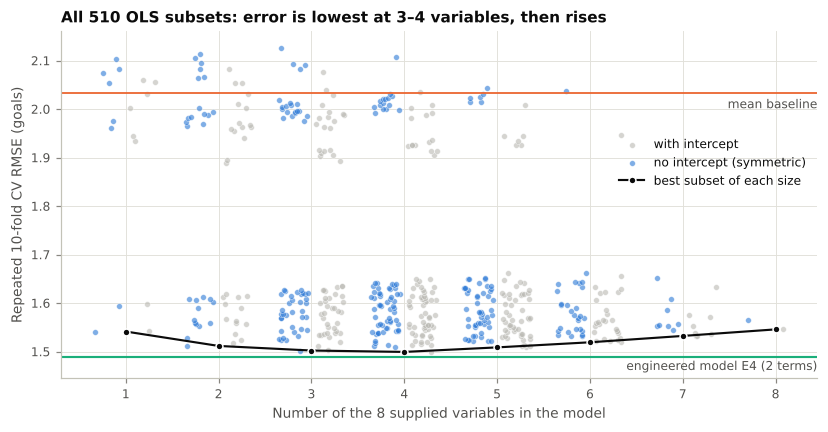

In [21]:
fig, ax = plt.subplots(figsize=(7.6, 4.0))
rng = np.random.default_rng(SEED)
for intercept, colour, lab in [(True, GREY, "with intercept"), (False, BLUE, "no intercept (symmetric)")]:
    sub = subsets[subsets.intercept == intercept]
    ax.scatter(sub.k + rng.uniform(-0.16, 0.16, len(sub)) + (0.2 if intercept else -0.2), sub.cv_rmse, s=14,
               color=colour, alpha=0.6, edgecolor="white", linewidth=0.4, label=lab)
best_k = subsets.groupby("k").cv_rmse.min()
ax.plot(best_k.index, best_k.values, color=INK, lw=1.4, marker="o", ms=4.5, mfc=INK, mec="white", mew=1,
        label="best subset of each size")
ax.axhline(base_tab.loc["Baseline: training mean", "cv_rmse"], color=ORANGE, lw=1.2)
ax.text(8.45, base_tab.loc["Baseline: training mean", "cv_rmse"] - 0.012, "mean baseline", ha="right", va="top",
        fontsize=8, color=INK2)
e4 = exp_tab.loc["E4  E3 + host_home_diff", "cv_rmse"]
ax.axhline(e4, color=AQUA, lw=1.4)
ax.text(8.45, e4 - 0.008, "engineered model E4 (2 terms)", ha="right", va="top", fontsize=8, color=INK2)
ax.set_ylim(1.445, 2.16)
ax.set(xlabel="Number of the 8 supplied variables in the model", ylabel="Repeated 10-fold CV RMSE (goals)",
       xticks=range(1, 9), title="All 510 OLS subsets: error is lowest at 3–4 variables, then rises")
ax.legend(loc="center right", bbox_to_anchor=(1.0, 0.62))
fig.tight_layout()
savefig(fig, "fig06_best_subset_search")

**Reading the search.**

* Squad value is in every one of the 100 best subsets and FIFA rank in 96 % of the best 25; `host_home_diff`
  is in about 70 %. The form variables, rest days and `same_confed` are rare at the top of the ranking.
* CV error is lowest with three or four variables and rises steadily as more are added: the bias–variance
  trade-off with a small sample.
* The best subset *with* an intercept includes `stage_ord`. This is the orientation artefact again: random
  folds cannot expose it, walk-forward validation can (Section 10).
* The engineered two-term model E4 (green line) is below **every one** of the 510 raw-variable subsets.
  Feature engineering guided by EDA beat brute-force selection.

Picking the winner of 510 models on the same CV used to score them is optimistic, so in the next section
best-subset selection is re-run *inside* each training fold (nested CV) to get its honest error.

## 10. Competing algorithms

All linear-regression variants taught for small, collinear data are compared on identical folds, together
with two non-linear learners as a sanity check on the linearity assumption. Tuning happens inside each
training fold.

| Family | Algorithm | What it tries to fix |
|---|---|---|
| Baselines | training mean; always a draw | scale of the problem |
| OLS | rank only; all 8 variables | reference |
| Subset selection | best subset chosen by inner CV | too many weak variables |
| Shrinkage | ridge, lasso, elastic net | collinearity and over-fitting |
| Robust | Huber regression | influence of blow-outs |
| Dimension reduction | principal-component regression, partial least squares | redundant pairs |
| Non-linear | random forest, gradient boosting, plain and symmetrised (prediction averaged with the mirrored match) | interactions and curvature |
| EDA-engineered | symmetric OLS on the strength index (E3, E4); symmetric ridge on all 8, plain and with feature-specific (weighted) shrinkage; nested selection among E3–E10 | orientation artefact + redundancy; selection optimism |

In [22]:
class BestSubsetCV(BaseEstimator, RegressorMixin):
    """OLS on the subset of columns that minimises inner K-fold CV error (exhaustive search)."""

    def __init__(self, n_splits=5, random_state=0):
        self.n_splits = n_splits
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y, float)
        folds = list(KFold(self.n_splits, shuffle=True, random_state=self.random_state).split(X))
        best = (np.inf, None)
        for k in range(1, X.shape[1] + 1):
            for cols in itertools.combinations(range(X.shape[1]), k):
                Xs = np.column_stack([np.ones(len(X)), X[:, cols]])
                sse = 0.0
                for tr, te in folds:
                    beta = np.linalg.lstsq(Xs[tr], y[tr], rcond=None)[0]
                    sse += ((y[te] - Xs[te] @ beta) ** 2).sum()
                if sse < best[0]:
                    best = (sse, cols)
        self.cols_ = best[1]
        Xs = np.column_stack([np.ones(len(X)), X[:, self.cols_]])
        self.beta_ = np.linalg.lstsq(Xs, y, rcond=None)[0]
        return self

    def predict(self, X):
        X = np.asarray(X, float)
        return np.column_stack([np.ones(len(X)), X[:, self.cols_]]) @ self.beta_


class CandidateSelectCV(BaseEstimator, RegressorMixin):
    """Symmetric OLS on whichever candidate column set has the lowest inner K-fold error.

    Used to price in the fact that the engineered model was itself chosen after comparing candidates."""

    def __init__(self, candidates=None, n_splits=5, random_state=0):
        self.candidates = candidates
        self.n_splits = n_splits
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y, float)
        folds = list(KFold(self.n_splits, shuffle=True, random_state=self.random_state).split(X))
        best = (np.inf, None)
        for cols in self.candidates:
            Xs = X[:, list(cols)]
            sse = sum(((y[te] - Xs[te] @ np.linalg.lstsq(Xs[tr], y[tr], rcond=None)[0]) ** 2).sum() for tr, te in folds)
            if sse < best[0]:
                best = (sse, list(cols))
        self.cols_ = best[1]
        self.beta_ = np.linalg.lstsq(X[:, self.cols_], y, rcond=None)[0]
        return self

    def predict(self, X):
        return np.asarray(X, float)[:, self.cols_] @ self.beta_


class Symmetrised(BaseEstimator, RegressorMixin):
    """Make any learner consistent with team order: prediction = (f(x) - f(mirror x)) / 2, where the mirror
    flips the six team-difference columns and keeps stage_ord and same_confed. No rows are added."""

    def __init__(self, base=None, odd=()):
        self.base = base
        self.odd = odd

    def fit(self, X, y):
        self.base_ = clone(self.base).fit(np.asarray(X, float), y)
        return self

    def predict(self, X):
        X = np.asarray(X, float)
        M = X.copy()
        M[:, list(self.odd)] *= -1
        return (self.base_.predict(X) - self.base_.predict(M)) / 2


ODD_IDX = tuple(range(len(ODD)))              # the first six columns of X8 flip sign
ALPHAS = np.logspace(-2, 3, 40)
scaled = lambda est: make_pipeline(StandardScaler(), est)
pcr = GridSearchCV(Pipeline([("sc", StandardScaler()), ("pca", PCA()), ("ols", LinearRegression())]),
                   {"pca__n_components": [1, 2, 3, 4, 6, 8]}, cv=INNER, scoring="neg_mean_squared_error")
pls = GridSearchCV(Pipeline([("sc", StandardScaler()), ("pls", PLSRegression())]),
                   {"pls__n_components": [1, 2, 3, 4]}, cv=INNER, scoring="neg_mean_squared_error")

df["strength_x_stage"] = df.strength * (df.stage_ord - 1)
SYM8 = ODD + ["strength_x_stage", "strength_x_same_confed"]       # all 8 variables, used symmetrically
sym_ridge = make_pipeline(StandardScaler(with_mean=False), RidgeCV(alphas=ALPHAS, fit_intercept=False))


class ColumnWeights(BaseEstimator, TransformerMixin):
    """Multiply the `weak` columns by w (0 < w <= 1). A ridge penalty then shrinks them 1/w² times harder
    than the other columns: feature-specific shrinkage that still keeps every variable in the model."""

    def __init__(self, weak=(), w=1.0):
        self.weak = weak
        self.w = w

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = np.array(X, dtype=float, copy=True)
        X[:, list(self.weak)] *= self.w
        return X


# all eight variables stay in; the six terms other than rank and value can be penalised harder (w tuned, w = 1 is plain ridge)
WEAK = tuple(i for i, c in enumerate(SYM8) if c not in ("log_rank_diff", "log_value_diff"))
weighted_sym_ridge = GridSearchCV(
    Pipeline([("sc", StandardScaler(with_mean=False)), ("cw", ColumnWeights(weak=WEAK)), ("ridge", Ridge(fit_intercept=False))]),
    {"cw__w": [0.05, 0.1, 0.25, 0.5, 1.0], "ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]},
    cv=INNER, scoring="neg_mean_squared_error")

# every engineered specification of Section 8 (E3-E10) as a candidate: strength alone, or strength + one term
CAND_COLS = ["strength", "host_home_diff", "gd_pg_diff", "ppg_diff", "rest_days_diff",
             "strength_x_knockout", "strength_x_same_confed", "strength_cubed"]
CANDIDATES = [(0,)] + [(0, j) for j in range(1, len(CAND_COLS))]

competitors = [
    ("Best subset (nested selection)", scaled(BestSubsetCV(random_state=SEED)), X8, "subset selection"),
    ("Ridge", scaled(RidgeCV(alphas=ALPHAS)), X8, "shrinkage"),
    ("Lasso", scaled(LassoCV(cv=INNER, random_state=SEED)), X8, "shrinkage"),
    ("Elastic net", scaled(ElasticNetCV(cv=INNER, l1_ratio=[0.2, 0.5, 0.8], random_state=SEED)), X8, "shrinkage"),
    ("Huber (robust)", scaled(HuberRegressor(max_iter=1000)), X8, "robust"),
    ("Principal-component regression", pcr, X8, "dimension reduction"),
    ("Partial least squares", pls, X8, "dimension reduction"),
    ("Random forest", RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=SEED), X8, "non-linear"),
    ("Gradient boosting", GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.05,
                                                    subsample=0.8, random_state=SEED), X8, "non-linear"),
    ("Random forest, symmetrised", Symmetrised(RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=SEED), ODD_IDX), X8, "non-linear"),
    ("Gradient boosting, symmetrised", Symmetrised(GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.05,
                                                                         subsample=0.8, random_state=SEED), ODD_IDX), X8, "non-linear"),
    ("Symmetric ridge: all 8 variables", sym_ridge, SYM8, "EDA-engineered"),
    ("Weighted symmetric ridge: all 8 variables", weighted_sym_ridge, SYM8, "EDA-engineered"),
    ("Engineered E3–E10, nested selection", CandidateSelectCV(CANDIDATES, random_state=SEED), CAND_COLS, "EDA-engineered"),
    ("Symmetric OLS: strength (E3)", OLS0, ["strength"], "EDA-engineered"),
    ("Symmetric OLS: strength + host (E4)", OLS0, ["strength", "host_home_diff"], "EDA-engineered"),
]
comp_rows = [score(name, est, cols, fam) for name, est, cols, fam in competitors]
board = pd.concat([base_tab.reset_index(), pd.DataFrame(comp_rows)]).set_index("model").sort_values("cv_rmse")
FINAL, REFERENCE = "Symmetric OLS: strength + host (E4)", "Full OLS: all 8 variables"
board["cv_gain_vs_full_ols_%"] = 100 * (1 - board.cv_rmse / board.loc[REFERENCE, "cv_rmse"])
board["wf_gain_vs_full_ols_%"] = 100 * (1 - board.wf_rmse / board.loc[REFERENCE, "wf_rmse"])
display(board)
board.to_csv(RES / "lr21_model_leaderboard.csv")

,family,n_terms,cv_rmse,cv_rmse_sd,cv_mae,cv_r2,wf_rmse,wf_mae,cv_gain_vs_full_ols_%,wf_gain_vs_full_ols_%
model,,,,,,,,,,
Symmetric OLS: strength + host (E4),EDA-engineered,2,1.489,0.012,1.150,0.453,1.433,1.084,3.656,21.143
Symmetric OLS: strength (E3),EDA-engineered,1,1.497,0.007,1.163,0.448,1.438,1.100,3.158,20.863
"Engineered E3–E10, nested selection",EDA-engineered,8,1.506,0.023,1.168,0.441,1.470,1.146,2.599,19.076
Symmetric ridge: all 8 variables,EDA-engineered,8,1.507,0.020,1.168,0.440,1.559,1.234,2.531,14.207
Weighted symmetric ridge: all 8 variables,EDA-engineered,8,1.509,0.021,1.172,0.439,1.453,1.134,2.406,20.009
Principal-component regression,dimension reduction,8,1.528,0.035,1.201,0.424,1.526,1.200,1.163,16.026
Ridge,shrinkage,8,1.535,0.021,1.191,0.419,1.625,1.253,0.711,10.566
Elastic net,shrinkage,8,1.540,0.025,1.197,0.415,1.614,1.243,0.361,11.179
Lasso,shrinkage,8,1.544,0.023,1.204,0.412,1.609,1.242,0.101,11.417


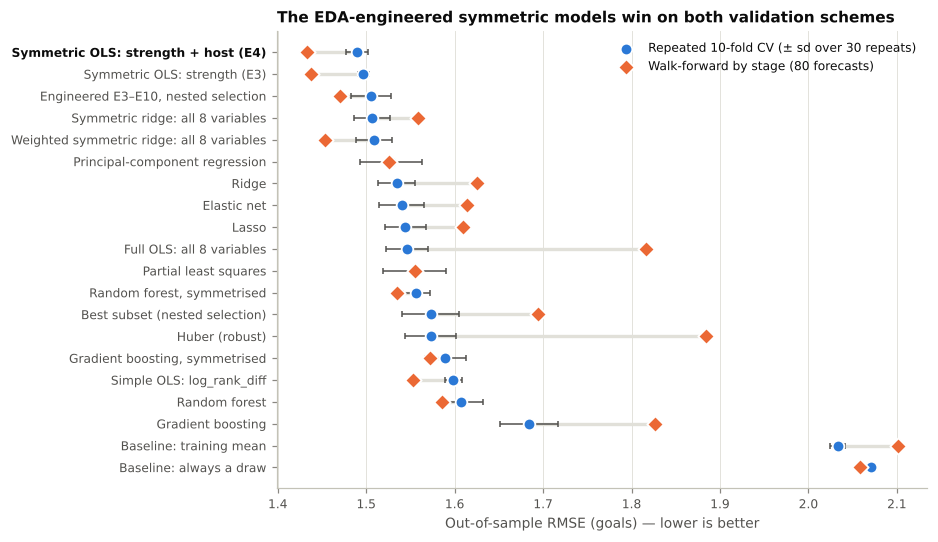

In [23]:
fig, ax = plt.subplots(figsize=(8.6, 5.0))
show = board.sort_values("cv_rmse", ascending=False)
ypos = np.arange(len(show))
ax.hlines(ypos, show[["cv_rmse", "wf_rmse"]].min(axis=1), show[["cv_rmse", "wf_rmse"]].max(axis=1), color=GRID, lw=2.2, zorder=1)
ax.errorbar(show.cv_rmse, ypos, xerr=show.cv_rmse_sd, fmt="none", ecolor=INK2, elinewidth=1, capsize=2, zorder=2)
ax.scatter(show.cv_rmse, ypos, s=58, color=BLUE, edgecolor="white", linewidth=1.2, zorder=3, label="Repeated 10-fold CV (± sd over 30 repeats)")
ax.scatter(show.wf_rmse, ypos, s=58, marker="D", color=ORANGE, edgecolor="white", linewidth=1.2, zorder=3, label="Walk-forward by stage (80 forecasts)")
ax.set_yticks(ypos); ax.set_yticklabels(show.index)
for lab in ax.get_yticklabels():
    if lab.get_text() == FINAL:
        lab.set_fontweight("bold"); lab.set_color(INK)
ax.set(xlabel="Out-of-sample RMSE (goals) — lower is better",
       title="The EDA-engineered symmetric models win on both validation schemes")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper right")
fig.tight_layout()
savefig(fig, "fig07_model_leaderboard")

### Is the improvement statistically meaningful?

Differences between models on 104 matches are small relative to the noise, so we test them rather than
just rank them. Two tests are used: the Nadeau–Bengio corrected t-test on the 300 fold-level errors (it
corrects for the overlap between training sets), and a paired bootstrap on the 80 walk-forward forecasts.

In [24]:
def paired_bootstrap_wf(a, b, n_boot=10000, seed=SEED):
    """Bootstrap the difference in walk-forward RMSE (a minus b) by resampling matches."""
    ea = ((y - STORE[a]["wf"])[wf_mask]) ** 2
    eb = ((y - STORE[b]["wf"])[wf_mask]) ** 2
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(ea), size=(n_boot, len(ea)))
    d = np.sqrt(ea[idx].mean(1)) - np.sqrt(eb[idx].mean(1))
    return np.sqrt(ea.mean()) - np.sqrt(eb.mean()), np.percentile(d, [2.5, 97.5]), (d >= 0).mean()

cmp_rows = []
for rival in ["Baseline: training mean", "Simple OLS: log_rank_diff", REFERENCE, "Ridge", "Lasso",
              "Best subset (nested selection)", "Random forest", "Weighted symmetric ridge: all 8 variables",
              "Engineered E3–E10, nested selection",
              "Symmetric OLS: strength (E3)"]:
    d_mse, t_stat, p_cv = corrected_ttest(FINAL, rival)
    d_wf, ci, p_boot = paired_bootstrap_wf(FINAL, rival)
    wins = (STORE[FINAL]["cv"]["rmse"] < STORE[rival]["cv"]["rmse"]).mean()
    cmp_rows.append(dict(final_model_vs=rival, d_cv_rmse=board.loc[FINAL, "cv_rmse"] - board.loc[rival, "cv_rmse"],
                         repeats_won=wins, corrected_t=t_stat, p_corrected_t=p_cv,
                         d_wf_rmse=d_wf, wf_ci_low=ci[0], wf_ci_high=ci[1], p_bootstrap_one_sided=p_boot))
cmp_tab = pd.DataFrame(cmp_rows).set_index("final_model_vs")
display(cmp_tab)

wf_stage = pd.DataFrame({
    name: [np.sqrt((((y - STORE[name]["wf"])[(df.stage_ord == s).to_numpy()]) ** 2).mean()) for s in WF_STAGES]
    for name in ["Baseline: training mean", REFERENCE, "Ridge", FINAL]}, index=[STAGE_NAME[s] for s in WF_STAGES])
wf_stage.insert(0, "matches", [int((df.stage_ord == s).sum()) for s in WF_STAGES])
display(wf_stage)

,d_cv_rmse,repeats_won,corrected_t,p_corrected_t,d_wf_rmse,wf_ci_low,wf_ci_high,p_bootstrap_one_sided
final_model_vs,,,,,,,,
Baseline: training mean,-0.544,1.000,-4.106,0.000,-0.668,-0.927,-0.404,0.000
Simple OLS: log_rank_diff,-0.109,1.000,-1.747,0.082,-0.120,-0.265,0.036,0.065
Full OLS: all 8 variables,-0.057,1.000,-1.233,0.219,-0.384,-0.592,-0.181,0.000
Ridge,-0.046,1.000,-1.218,0.224,-0.192,-0.334,-0.057,0.002
Lasso,-0.055,1.000,-1.368,0.172,-0.177,-0.333,-0.028,0.009
Best subset (nested selection),-0.084,1.000,-1.915,0.056,-0.261,-0.500,-0.064,0.003
Random forest,-0.118,1.000,-2.110,0.036,-0.153,-0.271,-0.031,0.008
Weighted symmetric ridge: all 8 variables,-0.019,0.833,-0.686,0.493,-0.021,-0.111,0.074,0.325
"Engineered E3–E10, nested selection",-0.016,0.767,-0.494,0.622,-0.038,-0.122,0.048,0.181


,matches,Baseline: training mean,Full OLS: all 8 variables,Ridge,Symmetric OLS: strength + host (E4)
MD2,24,2.311,1.737,1.813,1.675
MD3,24,2.409,2.230,1.686,1.335
R32,16,1.240,1.145,0.982,1.032
R16,8,2.198,1.926,1.893,1.791
QF,4,1.315,1.264,1.165,0.572
SF/3rd/F,4,1.968,1.955,1.908,1.586


**Comparison and recommendation.**

* **Every regression beats the baselines by a wide margin** (RMSE about 1.5 to 1.7 against 2.0), and the
  final model is significantly better than the mean baseline on both tests.
* **Among the eight-variable models the differences in random CV are small.** Ridge, lasso, elastic net and
  principal-component regression each shave a little off the full OLS. Partial least squares and Huber
  regression do not (the blow-outs are real results, not errors to be down-weighted). The tree ensembles
  are worse than plain OLS in CV, which confirms that the signal is linear and that 104 matches are too few
  for flexible learners. Making them consistent with team order helps (random forest 1.61 → 1.56 in CV, 1.59 →
  1.54 in walk-forward), but they still trail every symmetric linear model.
* **The symmetric, EDA-engineered models are best on both schemes.** The final model beats the full OLS in
  every one of the 30 CV repeats, although with this sample size the corrected t-test cannot separate the
  two (p ≈ 0.22). The honest reading is "consistently but modestly better in random CV".
* **Walk-forward validation is where the models separate.** Forecasting later stages from earlier ones, the
  final model has an RMSE of 1.43 against 1.82 for the full OLS, a 21 % reduction whose bootstrap interval
  excludes zero. Shrinkage only partly repairs the full model (ridge 1.62, lasso 1.61) because it shrinks
  the artefact instead of removing it. In the stage table the gap is largest on matchday 3 (2.23 against
  1.34), the first stage where the listing order reverses.
* **Nested best-subset selection is worse than the full OLS out of sample.** Choosing among 255 subsets on
  about 90 matches is itself a source of over-fitting.
* **The result survives pricing in our own model selection.** E4 was chosen after comparing several
  engineered candidates, so its own CV score is slightly optimistic. Re-running that choice inside every
  training fold (nested selection among E3–E10) gives 1.51 in CV and 1.47 in walk-forward: a little worse
  than E4's own figures, as expected, but still ahead of every conventional eight-variable model on both
  schemes.
* Adding the host term to the strength-only model changes the error very little (it wins 73 % of CV
  repeats; walk-forward difference 0.005). The two symmetric models are statistically indistinguishable.

**Recommendation.** Use the symmetric two-term OLS. It has the lowest error on both validation schemes, the
fewest parameters, coefficients that can each be explained in one sentence, and it is immune to the
orientation artefact by construction. If a model that uses all eight variables is required, use the weighted
symmetric ridge described below.

### Why does the simpler model win? A learning curve

If the full model only lacked data, its error should approach the simple model's as the training set grows.
We refit both on random training sets of increasing size (300 draws per size) and score them on the matches
left out.

,Full OLS (8 variables + intercept),Rank + value (2 variables + intercept),"Final model (strength + host, no intercept)"
training matches,,,
20,2.026,1.628,1.578
30,1.808,1.587,1.556
40,1.677,1.555,1.529
50,1.639,1.541,1.522
60,1.598,1.541,1.509
70,1.578,1.516,1.489
80,1.543,1.497,1.469
90,1.537,1.500,1.469


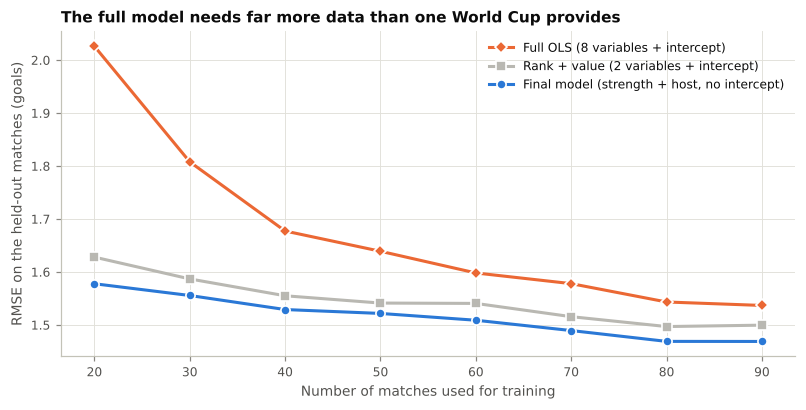

In [25]:
def learning_curve(cols, intercept, sizes, draws=300, seed=SEED):
    X = df[cols].to_numpy(float)
    if intercept:
        X = np.column_stack([np.ones(n), X])
    rng = np.random.default_rng(seed)
    out = []
    for m_train in sizes:
        errs = []
        for _ in range(draws):
            perm = rng.permutation(n); tr, te = perm[:m_train], perm[m_train:]
            beta = np.linalg.lstsq(X[tr], y[tr], rcond=None)[0]
            errs.append(np.sqrt(((y[te] - X[te] @ beta) ** 2).mean()))
        out.append(np.mean(errs))
    return np.array(out)

SIZES = [20, 30, 40, 50, 60, 70, 80, 90]
lc = pd.DataFrame({
    "Full OLS (8 variables + intercept)": learning_curve(X8, True, SIZES),
    "Rank + value (2 variables + intercept)": learning_curve(["log_rank_diff", "log_value_diff"], True, SIZES),
    "Final model (strength + host, no intercept)": learning_curve(["strength", "host_home_diff"], False, SIZES),
}, index=pd.Index(SIZES, name="training matches"))
display(lc)

fig, ax = plt.subplots(figsize=(7.4, 3.8))
for (name, col), colour, marker in zip(lc.items(), [ORANGE, GREY, BLUE], ["D", "s", "o"]):
    ax.plot(lc.index, col, color=colour, lw=2, marker=marker, ms=6, mec="white", mew=1.1, label=name)
ax.set(xlabel="Number of matches used for training", ylabel="RMSE on the held-out matches (goals)",
       title="The full model needs far more data than one World Cup provides")
ax.legend(loc="upper right")
fig.tight_layout()
savefig(fig, "fig07b_learning_curve")

**Reading the learning curve.** With 20 training matches the full model is no better than predicting the mean
(RMSE 2.03); with 90 it reaches 1.54. The final model is ahead at every size (1.58 falling to 1.47), and the gap
closes only slowly: 0.45 goals at 20 matches and still 0.07 at 90. Two things follow. First, most of the full
model's handicap is estimation variance from parameters that carry no signal, which is the bias–variance case
for parsimony. Second, the curves have not met by 90 matches, so one tournament is not enough data to estimate
nine parameters as well as two. The middle curve (rank and value kept separate, with an intercept) sits between
the other two, which shows that both engineering steps contribute: merging the pair and dropping the intercept.

### The best model that keeps all eight variables

If every supplied variable has to stay in the final equation, the strongest option is the **weighted symmetric
ridge**: no intercept, the six sign-flipping variables as main effects, the two sign-invariant ones as
moderators of strength, and a ridge penalty that is allowed to shrink the six weaker terms harder than rank
and value. The cell below refits it on all 104 matches to show what the tuning chose.

In [26]:
ws_fit = clone(weighted_sym_ridge).fit(df[SYM8].to_numpy(float), y)
best_pipe = ws_fit.best_estimator_
w_star, alpha_star = ws_fit.best_params_["cw__w"], ws_fit.best_params_["ridge__alpha"]
factors = np.where(np.isin(np.arange(len(SYM8)), WEAK), w_star, 1.0)
coef_original = best_pipe.named_steps["ridge"].coef_ * factors / best_pipe.named_steps["sc"].scale_
all8_tab = pd.DataFrame({"coefficient (original units)": coef_original,
                         "penalty relative to rank/value": np.where(factors < 1, 1 / w_star ** 2, 1.0)}, index=SYM8)
assert np.allclose(df[SYM8].to_numpy(float) @ coef_original, ws_fit.predict(df[SYM8].to_numpy(float)))
print(f"Chosen on all 104 matches: alpha = {alpha_star}, w = {w_star}")
display(all8_tab)
display(board.loc[["Weighted symmetric ridge: all 8 variables", "Symmetric ridge: all 8 variables", REFERENCE, FINAL],
                  ["cv_rmse", "cv_r2", "wf_rmse"]])
all8_tab.to_csv(RES / "lr21_all8_weighted_ridge_coefficients.csv")

Chosen on all 104 matches: alpha = 1, w = 0.1


,coefficient (original units),penalty relative to rank/value
log_rank_diff,0.349,1.000
log_value_diff,0.559,1.000
host_home_diff,0.447,100.000
ppg_diff,-0.076,100.000
gd_pg_diff,-0.054,100.000
rest_days_diff,0.103,100.000
strength_x_stage,-0.004,100.000
strength_x_same_confed,0.424,100.000


,cv_rmse,cv_r2,wf_rmse
model,,,
Weighted symmetric ridge: all 8 variables,1.509,0.439,1.453
Symmetric ridge: all 8 variables,1.507,0.440,1.559
Full OLS: all 8 variables,1.546,0.411,1.817
Symmetric OLS: strength + host (E4),1.489,0.453,1.433


**Reading.** The tuning chose α = 1 and w = 0.1, so the six weaker terms are penalised 100 times harder than
rank and value: the data themselves ask for the extra variables to be almost switched off. All eight variables
remain in the equation with non-zero coefficients. Rank, value and host keep the signs they have in the final
model, the two form terms are shrunk to nearly nothing (−0.08 and −0.05), and the largest surviving extra term is
the exploratory `strength × same_confed` interaction (0.42).

Against the plain symmetric ridge it is level in random CV (1.51) and clearly better in walk-forward (1.45
against 1.56; the full OLS scores 1.82). **This is the recommended fallback if the brief is read as requiring
every variable in the final equation.** The two-term model remains slightly more accurate and much easier to
explain.

### A stricter time test: whole-date folds and a final hold-out

The walk-forward test advances one tournament stage at a time. As a second, stricter design we use
expanding folds that never split a calendar date, and keep the last 16 matches (round of 16 onward)
out of every fit:

| Step | Fitted on | Scored on |
|---|---|---|
| Fold 1 | 44 matches to 22 June | 22 matches, 23–26 June |
| Fold 2 | 66 matches to 26 June | 13 matches, 27–30 June |
| Fold 3 | 79 matches to 30 June | 9 matches, 1–3 July |
| Hold-out | 88 matches to 3 July | 16 matches, 4–19 July |

In this test every tuned model also tunes its hyper-parameters *forward in time* (inner folds use only earlier
rows), so no inner fold ever trains on matches played after the ones it is scored on.

One caveat belongs up front: the *form* of the final model was decided with all 104 matches in view, so the
hold-out is a consistency check and not a pristine test. Its coefficients, however, come only from the
88 earlier matches. Hold-out R² is measured against the hold-out mean and can be negative.

,date_fold_n,date_fold_rmse,holdout_rmse,holdout_mae,holdout_r2
model,,,,,
Symmetric OLS: strength (E3),44,1.303,1.367,1.117,0.212
Symmetric OLS: strength + host (E4),44,1.307,1.521,1.194,0.024
Weighted symmetric ridge: all 8 variables,44,1.312,1.518,1.227,0.028
"Random forest, symmetrised",44,1.314,1.394,1.105,0.181
Simple OLS: log_rank_diff,44,1.400,1.545,1.239,-0.007
Symmetric ridge: all 8 variables,44,1.421,1.666,1.350,-0.170
Lasso,44,1.431,1.877,1.520,-0.486
Principal-component regression,44,1.434,1.890,1.536,-0.507
Ridge,44,1.466,1.825,1.483,-0.405


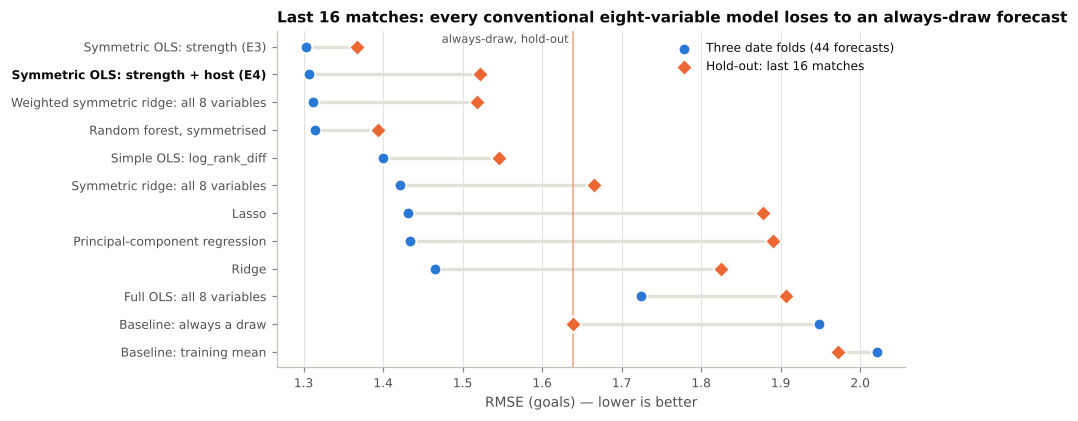

In [27]:
DATE_FOLDS = [("2026-06-22", "2026-06-23", "2026-06-26"), ("2026-06-26", "2026-06-27", "2026-06-30"),
              ("2026-06-30", "2026-07-01", "2026-07-03")]
dev_mask = (df.date <= "2026-07-03").to_numpy()
hold_mask = ~dev_mask
assert dev_mask.sum() == 88 and hold_mask.sum() == 16 and (df.stage_ord[hold_mask] >= 5).all()
HOLD_PRED = {}

def time_inner(est):
    """Copy of `est` whose inner tuning folds run forward in time (rows are in date order)."""
    est = clone(est)
    keys = [k for k in est.get_params(deep=True) if k == "cv" or k.endswith("__cv")]
    if keys:
        est.set_params(**{k: TimeSeriesSplit(n_splits=3) for k in keys})
    return est

def date_protocol(name):
    est, cols = time_inner(STORE[name]["est"]), STORE[name]["cols"]
    X = df[cols].to_numpy(float)
    pred = np.full(n, np.nan)
    for train_end, val_start, val_end in DATE_FOLDS:
        tr = (df.date <= train_end).to_numpy()
        te = ((df.date >= val_start) & (df.date <= val_end)).to_numpy()
        pred[te] = clone(est).fit(X[tr], y[tr]).predict(X[te])
    val = ~np.isnan(pred)
    hold = clone(est).fit(X[dev_mask], y[dev_mask]).predict(X[hold_mask])
    HOLD_PRED[name] = hold
    e_val, e_hold = (y - pred)[val], y[hold_mask] - hold
    return dict(model=name, date_fold_n=int(val.sum()), date_fold_rmse=np.sqrt((e_val ** 2).mean()),
                holdout_rmse=np.sqrt((e_hold ** 2).mean()), holdout_mae=np.abs(e_hold).mean(),
                holdout_r2=1 - (e_hold ** 2).sum() / ((y[hold_mask] - y[hold_mask].mean()) ** 2).sum())

DATE_MODELS = ["Baseline: always a draw", "Baseline: training mean", "Simple OLS: log_rank_diff", REFERENCE, "Ridge",
               "Lasso", "Principal-component regression", "Symmetric ridge: all 8 variables",
               "Weighted symmetric ridge: all 8 variables", "Random forest, symmetrised", "Symmetric OLS: strength (E3)", FINAL]
date_tab = pd.DataFrame([date_protocol(m) for m in DATE_MODELS]).set_index("model").sort_values("date_fold_rmse")
display(date_tab)
date_tab.to_csv(RES / "lr21_date_folds_and_holdout.csv")

fig, ax = plt.subplots(figsize=(8.4, 3.9))
show = date_tab.sort_values("date_fold_rmse", ascending=False)
ypos = np.arange(len(show))
ax.hlines(ypos, show[["date_fold_rmse", "holdout_rmse"]].min(axis=1), show[["date_fold_rmse", "holdout_rmse"]].max(axis=1), color=GRID, lw=2.2, zorder=1)
ax.scatter(show.date_fold_rmse, ypos, s=58, color=BLUE, edgecolor="white", linewidth=1.2, zorder=3, label="Three date folds (44 forecasts)")
ax.scatter(show.holdout_rmse, ypos, s=58, marker="D", color=ORANGE, edgecolor="white", linewidth=1.2, zorder=3, label="Hold-out: last 16 matches")
ax.set_yticks(ypos); ax.set_yticklabels(show.index)
for lab in ax.get_yticklabels():
    if lab.get_text() == FINAL:
        lab.set_fontweight("bold"); lab.set_color(INK)
ax.set(xlabel="RMSE (goals) — lower is better", title="Last 16 matches: every conventional eight-variable model loses to an always-draw forecast")
draw_hold = date_tab.loc["Baseline: always a draw", "holdout_rmse"]
ax.axvline(draw_hold, color=ORANGE, lw=1, alpha=0.6)
ax.text(draw_hold - 0.006, len(show) - 0.75, "always-draw, hold-out", fontsize=7.5, color=INK2, va="center", ha="right")
ax.grid(axis="y", visible=False); ax.legend(loc="upper right")
fig.tight_layout()
savefig(fig, "fig07c_date_folds_and_holdout")

**Reading the date-based test.**

* **Date folds (44 forecasts).** Four team-order-consistent models lead, almost tied (1.30–1.31): strength
  only, the final model, the weighted symmetric ridge and the symmetrised random forest. The rank-only
  regression, the plain symmetric ridge and the conventional eight-variable models follow (1.40–1.47), and the
  full OLS is last among the regressions (1.73).
* **Hold-out (last 16 matches).** This is a harder test. Five models beat the "always a draw" forecast (1.64):
  strength only (1.37, R² = +0.21), the symmetrised random forest (1.39, +0.18), the weighted symmetric ridge
  (1.52, +0.03), the final model (1.52, +0.02) and the rank-only regression (1.55, −0.01). The conventional
  eight-variable models and the plain symmetric ridge are worse than predicting a draw (1.67–1.91): their
  coefficients on stage, confederation and form misfire on rounds the model has never seen. Strong shrinkage
  of those terms, tuned forward in time, is what rescues the weighted symmetric ridge.
* **The host term costs accuracy here.** The only two host matches in the hold-out were both lost by the host
  (Mexico against England and the USA against Belgium in the round of 16), so the strength-only model does
  better on these 16 matches. We keep the two-term model as the main specification because that choice was
  fixed by the adoption rule in Section 8 before this test was run; re-selecting on a 16-match hold-out would
  turn the hold-out into training data. The practical message is that the two symmetric models are
  interchangeable and that the host effect should not be relied on.
* Sixteen matches is a small sample, and R² measured against a 16-match mean is unstable. These figures show
  direction, not precise accuracy.

## 11. Final model: estimation and inference

$$\widehat{\text{goal\_diff}} = b_1 \cdot \text{strength} + b_2 \cdot \text{host\_home\_diff}, \qquad
\text{strength} = \tfrac12\,(\text{log\_rank\_diff} + \text{log\_value\_diff})$$

**`strength` is not a ninth variable.** It is built from two of the eight original variables, `log_rank_diff` and `log_value_diff`, combined with equal weights (their plain average; Section 8 shows equal weights are not rejected, p = 0.59). No new data enter the model, so the final model uses three of the eight original variables: `log_rank_diff`, `log_value_diff` (both through `strength`) and `host_home_diff`.

In [28]:
FINAL_COLS = ["strength", "host_home_diff"]
Xf = df[FINAL_COLS]
final = sm.OLS(y, Xf).fit()
final_hc3 = final.get_robustcov_results("HC3")

rng = np.random.default_rng(SEED)
B_BOOT = 5000
boot = np.empty((B_BOOT, 2))
Xf_np = Xf.to_numpy(float)
for b in range(B_BOOT):
    i = rng.integers(0, n, n)
    boot[b] = np.linalg.lstsq(Xf_np[i], y[i], rcond=None)[0]

# matches on the same date share conditions (and some teams), so also cluster the standard errors by date
date_groups = pd.factorize(df.date)[0]
final_cluster = sm.OLS(y, Xf).fit(cov_type="cluster", cov_kwds={"groups": date_groups})

coef_tab = pd.DataFrame({
    "coef": final.params, "std_err": final.bse, "t": final.tvalues, "p": final.pvalues,
    "ci95_low": final.conf_int()[0], "ci95_high": final.conf_int()[1],
    "p_HC3_robust": final_hc3.pvalues, "p_date_cluster": final_cluster.pvalues,
    "boot_ci_low": np.percentile(boot, 2.5, axis=0), "boot_ci_high": np.percentile(boot, 97.5, axis=0),
    "boot_share_positive": (boot > 0).mean(0),
})
display(coef_tab)
print(f"Date clusters: {date_groups.max() + 1} match dates")
coef_tab.to_csv(RES / "lr21_final_model_coefficients.csv")

sse = float((final.resid ** 2).sum())
r2_centered = 1 - sse / SST
sigma = float(np.sqrt(final.mse_resid))
with_const = sm.OLS(y, sm.add_constant(Xf)).fit()
# F-test of the final model (2 parameters) against the full OLS (9 parameters): are the 7 extra parameters needed?
f_stat = ((final.ssr - ols8.ssr) / (final.df_resid - ols8.df_resid)) / (ols8.ssr / ols8.df_resid)
p_f = stats.f.sf(f_stat, final.df_resid - ols8.df_resid, ols8.df_resid)

fit_tab = pd.DataFrame({
    "Full OLS (8 variables + intercept)": [9, ols8.rsquared, ols8.rsquared_adj, np.sqrt(ols8.mse_resid), ols8.aic, ols8.bic,
                                           board.loc[REFERENCE, "cv_rmse"], board.loc[REFERENCE, "cv_r2"], board.loc[REFERENCE, "wf_rmse"]],
    "Final model (strength + host)": [2, r2_centered, 1 - (sse / final.df_resid) / (SST / (n - 1)), sigma, final.aic, final.bic,
                                      board.loc[FINAL, "cv_rmse"], board.loc[FINAL, "cv_r2"], board.loc[FINAL, "wf_rmse"]],
}, index=["parameters", "R2 in-sample (centred)", "adjusted R2", "residual sd (goals)", "AIC", "BIC",
          "CV RMSE", "CV R2", "walk-forward RMSE"])
display(fit_tab)
print(f"Intercept if added back: {with_const.params['const']:+.3f} (p = {with_const.pvalues['const']:.3f}) -> not needed")
print(f"F-test, final vs full model: F({final.df_resid - ols8.df_resid:.0f}, {ols8.df_resid:.0f}) = {f_stat:.2f}, "
      f"p = {p_f:.3f} -> the seven extra parameters add nothing significant")
print(f"Effect of doubling both the rank ratio and the value ratio: {final.params['strength'] * np.log(2):+.2f} goals")
print(f"One sd of strength ({df.strength.std():.2f}) is worth {final.params['strength'] * df.strength.std():+.2f} goals")

,coef,std_err,t,p,ci95_low,ci95_high,p_HC3_robust,p_date_cluster,boot_ci_low,boot_ci_high,boot_share_positive
strength,0.905,0.091,9.899,0.000,0.723,1.086,0.000,0.000,0.711,1.117,1.000
host_home_diff,0.818,0.407,2.007,0.047,0.010,1.626,0.125,0.056,-0.149,1.854,0.952


Date clusters: 34 match dates


,Full OLS (8 variables + intercept),Final model (strength + host)
parameters,9.000,2.000
R2 in-sample (centred),0.517,0.482
adjusted R2,0.477,0.477
residual sd (goals),1.464,1.464
AIC,383.057,376.419
BIC,406.856,381.708
CV RMSE,1.546,1.489
CV R2,0.411,0.453
walk-forward RMSE,1.817,1.433


Intercept if added back: +0.103 (p = 0.493) -> not needed
F-test, final vs full model: F(7, 95) = 1.00, p = 0.439 -> the seven extra parameters add nothing significant
Effect of doubling both the rank ratio and the value ratio: +0.63 goals
One sd of strength (1.54) is worth +1.39 goals


In [29]:
# Permutation test: could a CV error this low arise if the predictors were unrelated to the result?
rng = np.random.default_rng(SEED)
one_rep = SPLITS[:N_SPLITS]

def cv_rmse_once(target):
    pred = np.empty(n)
    for tr, te in one_rep:
        pred[te] = Xf_np[te] @ np.linalg.lstsq(Xf_np[tr], target[tr], rcond=None)[0]
    return np.sqrt(((target - pred) ** 2).mean())

obs_rmse = cv_rmse_once(y)
perm_rmse = np.array([cv_rmse_once(rng.permutation(y)) for _ in range(2000)])
p_perm = (1 + (perm_rmse <= obs_rmse).sum()) / (1 + len(perm_rmse))
print(f"Observed 10-fold CV RMSE = {obs_rmse:.3f}; permuted targets: mean {perm_rmse.mean():.3f}, "
      f"minimum {perm_rmse.min():.3f}; permutation p = {p_perm:.4f}")

Observed 10-fold CV RMSE = 1.498; permuted targets: mean 2.092, minimum 1.924; permutation p = 0.0005


**Interpretation.**

* **Strength.** The coefficient is about 0.90 goals per unit of the index (95 % CI roughly 0.72–1.09; the
  robust and bootstrap intervals agree). In plain terms: when a team's FIFA-rank ratio and squad-value ratio
  are both twice as favourable as its opponent's, it is expected to win by about 0.6 of a goal more; a
  one-standard-deviation edge in strength is worth about 1.4 goals.
* **Host advantage.** A host nation playing in its own country is expected to gain about 0.8 of a goal.
  The classical 95 % interval just excludes zero (p ≈ 0.05), but the heteroscedasticity-robust p-value is
  about 0.12, the date-clustered p-value about 0.06, and the bootstrap interval includes zero. With only 13 host matches the honest statement is
  that the estimate is consistent with the well-documented home advantage in football, but this tournament
  alone cannot confirm its size.
* **No intercept is needed**: when added back it is +0.10 and not significant.
* **Parsimony costs nothing.** The F-test cannot distinguish the 2-parameter model from the 9-parameter full
  model (p ≈ 0.44), and AIC and BIC both prefer the smaller one (BIC by about 25 points).
* **The signal is real.** None of 2,000 permutations of the target produced a CV error as low as the
  observed one (p < 0.001).

The centred in-sample R² is about 0.48 and the cross-validated R² about 0.45, so the two are now close:
unlike the full model, the final model is not flattering itself.

## 12. Diagnostics

In [30]:
infl = final.get_influence()
fitted, resid = final.fittedvalues.to_numpy(), final.resid.to_numpy()
stud = infl.resid_studentized_external
lev, cooks = infl.hat_matrix_diag, infl.cooks_distance[0]
Xdiag = sm.add_constant(Xf)

diag_tests = pd.DataFrame([
    ("Normality of residuals", "Shapiro-Wilk", stats.shapiro(resid).pvalue),
    ("Normality of residuals", "Jarque-Bera", stats.jarque_bera(resid).pvalue),
    ("Constant variance", "Breusch-Pagan", het_breuschpagan(resid, Xdiag)[1]),
    ("Constant variance", "White", het_white(resid, Xdiag)[1]),
    ("Constant variance (group stage vs knockout)", "Levene", stats.levene(resid[~ko], resid[ko]).pvalue),
    ("Linearity / functional form", "Ramsey RESET (powers 2-3)", float(linear_reset(with_const, power=3, use_f=True).pvalue)),
    ("Zero-mean residuals", "one-sample t", stats.ttest_1samp(resid, 0).pvalue),
], columns=["assumption", "test", "p_value"])
diag_tests["verdict at 5%"] = np.where(diag_tests.p_value > 0.05, "not rejected", "REJECTED")
display(diag_tests)
print(f"Durbin-Watson (matches in date order) = {durbin_watson(resid):.2f}  (2 = no serial correlation)")
print(f"Residual sd: group stage {resid[~ko].std(ddof=1):.2f}, knockout {resid[ko].std(ddof=1):.2f}")
vif_final = [variance_inflation_factor(Xf.to_numpy(float), i) for i in range(2)]
print(f"VIF in the final model: strength {vif_final[0]:.2f}, host_home_diff {vif_final[1]:.2f}")

,assumption,test,p_value,verdict at 5%
0,Normality of residuals,Shapiro-Wilk,0.485,not rejected
1,Normality of residuals,Jarque-Bera,0.862,not rejected
2,Constant variance,Breusch-Pagan,0.174,not rejected
3,Constant variance,White,0.224,not rejected
4,Constant variance (group stage vs knockout),Levene,0.252,not rejected
5,Linearity / functional form,Ramsey RESET (powers 2-3),0.346,not rejected
6,Zero-mean residuals,one-sample t,0.507,not rejected


Durbin-Watson (matches in date order) = 1.99  (2 = no serial correlation)
Residual sd: group stage 1.51, knockout 1.25
VIF in the final model: strength 1.00, host_home_diff 1.00


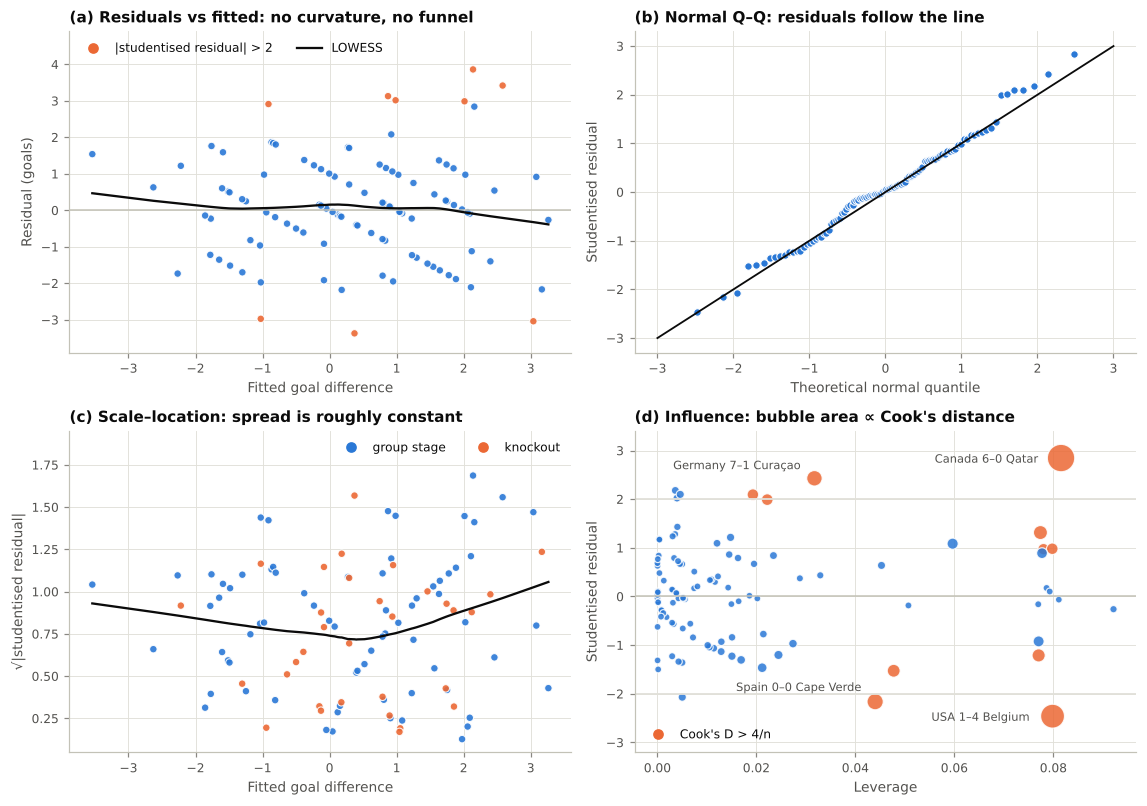

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.4))
flag = np.abs(stud) > 2

ax = axes[0, 0]
ax.axhline(0, color=AXIS, lw=1)
ax.scatter(fitted, resid, s=24, color=np.where(flag, ORANGE, BLUE), edgecolor="white", linewidth=0.7, alpha=0.9)
sm_fit = lowess(resid, fitted, frac=0.7)
ax.plot(sm_fit[:, 0], sm_fit[:, 1], color=INK, lw=1.5)
ax.set(xlabel="Fitted goal difference", ylabel="Residual (goals)", ylim=(-3.9, 4.9),
       title="(a) Residuals vs fitted: no curvature, no funnel")
ax.legend(handles=[Line2D([], [], marker="o", color=ORANGE, lw=0, label="|studentised residual| > 2"),
                   Line2D([], [], color=INK, lw=1.5, label="LOWESS")], loc="upper left", ncol=2)

ax = axes[0, 1]
osm, osr = stats.probplot(stud, dist="norm", fit=False)
ax.plot([-3, 3], [-3, 3], color=INK, lw=1.2)
ax.scatter(osm, osr, s=24, color=BLUE, edgecolor="white", linewidth=0.7)
ax.set(xlabel="Theoretical normal quantile", ylabel="Studentised residual", title="(b) Normal Q–Q: residuals follow the line")

ax = axes[1, 0]
ax.scatter(fitted, np.sqrt(np.abs(stud)), s=24, color=np.where(ko, ORANGE, BLUE), edgecolor="white", linewidth=0.7, alpha=0.9)
sm_fit = lowess(np.sqrt(np.abs(stud)), fitted, frac=0.7)
ax.plot(sm_fit[:, 0], sm_fit[:, 1], color=INK, lw=1.5)
ax.set(xlabel="Fitted goal difference", ylabel="√|studentised residual|", ylim=(0.05, 1.95),
       title="(c) Scale–location: spread is roughly constant")
ax.legend(handles=[Line2D([], [], marker="o", color=BLUE, lw=0, label="group stage"),
                   Line2D([], [], marker="o", color=ORANGE, lw=0, label="knockout")], loc="upper right", ncol=2)

ax = axes[1, 1]
ax.axhline(0, color=AXIS, lw=1)
ax.axhline(2, color=GRID, lw=1.2); ax.axhline(-2, color=GRID, lw=1.2)
ax.scatter(lev, stud, s=20 + 900 * cooks, color=np.where(cooks > 4 / n, ORANGE, BLUE), edgecolor="white", linewidth=0.8, alpha=0.85)
top = np.argsort(cooks)[::-1][:4]
offsets = {0: (-15, -3), 1: (-15, -3), 2: (-9, 7), 3: (-9, 6)}
for rank_i, i in enumerate(top):
    dx, dy = offsets[rank_i]
    ax.annotate(df.label[i], (lev[i], stud[i]), xytext=(dx, dy), textcoords="offset points", fontsize=7.5,
                color=INK2, ha="right" if dx < 0 else "left")
ax.set(xlabel="Leverage", ylabel="Studentised residual", ylim=(-3.2, 3.4),
       title="(d) Influence: bubble area ∝ Cook's distance")
ax.legend(handles=[Line2D([], [], marker="o", color=ORANGE, lw=0, label="Cook's D > 4/n")], loc="lower left")
fig.tight_layout()
savefig(fig, "fig08_diagnostics")

In [32]:
infl_tab = (df[["match_id", "stage", "label", "strength", "host_home_diff"]]
            .assign(fitted=fitted, residual=resid, studentised=stud, leverage=lev, cooks_d=cooks)
            .sort_values("cooks_d", ascending=False).head(8).set_index("match_id"))
display(infl_tab)

keep = cooks <= 4 / n
refit = sm.OLS(y[keep], Xf[keep]).fit()
huber_final = HuberRegressor(fit_intercept=False, max_iter=1000).fit(Xf_np, y)
robust_tab = pd.DataFrame({
    "all 104 matches (OLS)": final.params,
    f"without {int((~keep).sum())} matches with Cook's D > 4/n": refit.params,
    "Huber robust fit": pd.Series(huber_final.coef_, index=FINAL_COLS),
})
display(robust_tab)
print(f"|studentised residual| > 2: {int((np.abs(stud) > 2).sum())} matches "
      f"({(np.abs(stud) > 2).mean():.1%}; about 5% expected) | > 3: {int((np.abs(stud) > 3).sum())}")

,stage,label,strength,host_home_diff,fitted,residual,studentised,leverage,cooks_d
match_id,,,,,,,,,
28,MD2,Canada 6–0 Qatar,1.462,1,2.140,3.860,2.845,0.082,0.336
94,R16,USA 1–4 Belgium,-0.493,1,0.372,-3.372,-2.459,0.080,0.250
15,MD1,Spain 0–0 Cape Verde,3.361,0,3.040,-3.040,-2.161,0.044,0.104
9,MD1,Germany 7–1 Curaçao,2.854,0,2.581,3.419,2.429,0.032,0.092
55,MD3,Turkey 3–2 USA,-0.026,-1,-0.841,1.841,1.314,0.077,0.072
49,MD3,Czech Republic 0–3 Mexico,-0.535,-1,-1.301,-1.699,-1.210,0.077,0.061
86,R32,Argentina 3–2 Cape Verde,3.501,0,3.167,-2.167,-1.526,0.048,0.058
45,MD2,Portugal 5–0 Uzbekistan,2.387,0,2.159,2.841,1.991,0.022,0.044


,all 104 matches (OLS),without 11 matches with Cook's D > 4/n,Huber robust fit
strength,0.905,0.832,0.856
host_home_diff,0.818,0.800,0.790


|studentised residual| > 2: 9 matches (8.7%; about 5% expected) | > 3: 0


**Diagnostics verdict.**

* **Linearity, normality, constant variance and zero-mean residuals are all supported**: no formal test
  rejects at the 5 % level, and the four plots show no curvature, funnel or heavy tails. Durbin–Watson is
  about 2, so residuals of consecutive matches are uncorrelated. Classical OLS inference is therefore
  appropriate, and no further transformation is warranted.
* **No single match drives the result.** About 9 % of matches have |studentised residual| > 2 and none
  exceeds 3. The most influential matches are host games (USA 1–4 Belgium, Canada 6–0 Qatar), which is
  expected because only 13 matches inform the host coefficient. Refitting without the high-Cook's-distance
  matches, or with a Huber loss, moves the strength coefficient by less than 0.1 and leaves the host
  coefficient close to 0.8. The conclusions do not depend on a handful of results.
* These "outliers" are genuine football results, not data errors, so they are kept.

## 13. What the model can and cannot do

In [33]:
# Leave-one-out predictions with 95% prediction intervals (each match predicted by a model that never saw it)
loo_pred, loo_lo, loo_hi = np.empty(n), np.empty(n), np.empty(n)
for i in range(n):
    m = np.ones(n, bool); m[i] = False
    f_i = sm.OLS(y[m], Xf[m]).fit()
    fr = f_i.get_prediction(Xf.iloc[[i]]).summary_frame(alpha=0.05)
    loo_pred[i], loo_lo[i], loo_hi[i] = fr["mean"].iloc[0], fr["obs_ci_lower"].iloc[0], fr["obs_ci_upper"].iloc[0]
loo_err = y - loo_pred
decisive = y != 0
naive_pick = np.sign(df.log_rank_diff.to_numpy())               # naive rule: the better FIFA-ranked team wins
practical = pd.Series({
    "LOO RMSE (goals)": np.sqrt((loo_err ** 2).mean()),
    "LOO MAE (goals)": np.abs(loo_err).mean(),
    "LOO R2": 1 - (loo_err ** 2).sum() / SST,
    "predictions within 1 goal": (np.abs(loo_err) <= 1).mean(),
    "predictions within 2 goals": (np.abs(loo_err) <= 2).mean(),
    "correct winner among the %d decisive matches" % decisive.sum(): (np.sign(loo_pred[decisive]) == np.sign(y[decisive])).mean(),
    "... same, naive rule 'better FIFA rank wins'": (naive_pick[decisive] == np.sign(y[decisive])).mean(),
    "coverage of the 95% prediction interval": ((y >= loo_lo) & (y <= loo_hi)).mean(),
    "average half-width of the 95% prediction interval (goals)": ((loo_hi - loo_lo) / 2).mean(),
}, name="final model")
display(practical.to_frame())

surprises = (df[["match_id", "stage", "label", "strength"]].assign(predicted=loo_pred, actual=y, error=loo_err)
             .reindex(pd.Series(np.abs(loo_err)).sort_values(ascending=False).index).head(8).set_index("match_id"))
display(surprises)

,final model
LOO RMSE (goals),1.491
LOO MAE (goals),1.151
LOO R2,0.452
predictions within 1 goal,0.510
predictions within 2 goals,0.865
correct winner among the 80 decisive matches,0.850
"... same, naive rule 'better FIFA rank wins'",0.850
coverage of the 95% prediction interval,0.904
average half-width of the 95% prediction interval (goals),2.933


,stage,label,strength,predicted,actual,error
match_id,,,,,,
28,MD2,Canada 6–0 Qatar,1.462,1.797,6.000,4.203
94,R16,USA 1–4 Belgium,-0.493,0.664,-3.000,-3.664
9,MD1,Germany 7–1 Curaçao,2.854,2.469,6.000,3.531
15,MD1,Spain 0–0 Cape Verde,3.361,3.180,0.000,-3.180
12,MD1,Sweden 5–1 Tunisia,0.964,0.861,4.000,3.139
66,MD3,Senegal 5–0 Iraq,2.225,1.954,5.000,3.046
35,MD2,Netherlands 5–1 Sweden,1.089,0.971,4.000,3.029
36,MD2,Tunisia 0–4 Japan,-1.135,-1.012,-4.000,-2.988


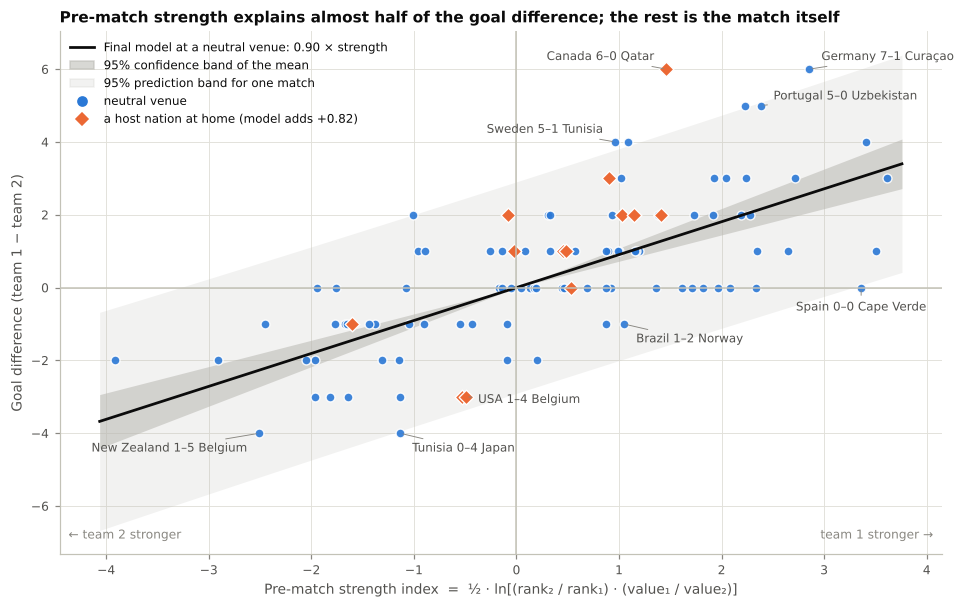

In [34]:
fig, ax = plt.subplots(figsize=(9.0, 5.6))
gx = np.linspace(df.strength.min() - 0.15, df.strength.max() + 0.15, 200)
band = final.get_prediction(pd.DataFrame({"strength": gx, "host_home_diff": 0.0})).summary_frame(alpha=0.05)
ax.fill_between(gx, band.obs_ci_lower, band.obs_ci_upper, color=GREY, alpha=0.18, lw=0)
ax.fill_between(gx, band.mean_ci_lower, band.mean_ci_upper, color=GREY, alpha=0.55, lw=0)
ax.plot(gx, band["mean"], color=INK, lw=1.8)
ax.axhline(0, color=AXIS, lw=1); ax.axvline(0, color=AXIS, lw=1)
host = (df.host_home_diff != 0).to_numpy()
ax.scatter(df.strength[~host], y[~host], s=34, color=BLUE, edgecolor="white", linewidth=0.9, alpha=0.9)
ax.scatter(df.strength[host], y[host], s=46, marker="D", color=ORANGE, edgecolor="white", linewidth=0.9)
label_pos = {  # match_id -> (dx, dy, ha) hand-placed so labels do not collide
    28: (-8, 6, "right"), 9: (8, 6, "left"), 15: (0, -15, "center"), 94: (8, -4, "left"),
    45: (8, 4, "left"), 12: (-8, 6, "right"), 36: (8, -12, "left"), 91: (8, -12, "left"), 62: (-8, -12, "right"),
}
for mid, (dx, dy, ha) in label_pos.items():
    r = df.loc[df.match_id == mid].iloc[0]
    ax.annotate(r.label, (r.strength, r.goal_diff), xytext=(dx, dy), textcoords="offset points", fontsize=7.8,
                color=INK2, ha=ha, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6))
ax.text(0.99, 0.03, "team 1 stronger →", transform=ax.transAxes, ha="right", fontsize=8, color=MUTED)
ax.text(0.01, 0.03, "← team 2 stronger", transform=ax.transAxes, ha="left", fontsize=8, color=MUTED)
ax.set(xlabel="Pre-match strength index  =  ½ · ln[(rank₂ / rank₁) · (value₁ / value₂)]",
       ylabel="Goal difference (team 1 − team 2)",
       title="Pre-match strength explains almost half of the goal difference; the rest is the match itself")
ax.legend(handles=[
    Line2D([], [], color=INK, lw=1.8, label=f"Final model at a neutral venue: {final.params['strength']:.2f} × strength"),
    mpl.patches.Patch(color=GREY, alpha=0.55, label="95% confidence band of the mean"),
    mpl.patches.Patch(color=GREY, alpha=0.18, label="95% prediction band for one match"),
    Line2D([], [], marker="o", color=BLUE, lw=0, label="neutral venue"),
    Line2D([], [], marker="D", color=ORANGE, lw=0, label=f"a host nation at home (model adds {final.params['host_home_diff']:+.2f})"),
], loc="upper left", fontsize=7.8)
fig.tight_layout()
savefig(fig, "fig09_expectation_vs_reality")

**Practical reading.**

* For a match it has never seen, the model's typical miss is a little over one goal (MAE ≈ 1.15), half of
  the predictions land within one goal of the result and 87 % within two.
* It names the correct winner in 85 % of the 80 matches that produced one. That is exactly what the naive
  rule "the better-ranked team wins" achieves, so the regression adds nothing for picking winners. What it
  adds is the *size* of the expected margin and a calibrated range around it, which the naive rule cannot give.
* The 95 % prediction interval is about ±2.9 goals wide and covered 90 % of held-out results (94 of 104),
  a little under the nominal 95 %. The shortfall comes from the handful of blow-outs in the right tail seen
  in Section 2, so the stated uncertainty is slightly optimistic for one-sided matches. The width itself is
  the model's main limitation: pre-match information narrows the range of plausible results, it does not
  pin down a scoreline.
* The largest misses are the tournament's genuine shocks: Canada 6–0 Qatar, Germany 7–1 Curaçao and Sweden
  5–1 Tunisia on the upside; USA 1–4 Belgium, Spain 0–0 Cape Verde and Tunisia 0–4 Japan on the downside.
  Nothing in the pre-match data separates them from ordinary matches, which is why they sit in the tails of
  the prediction band and do not point to a missing variable.

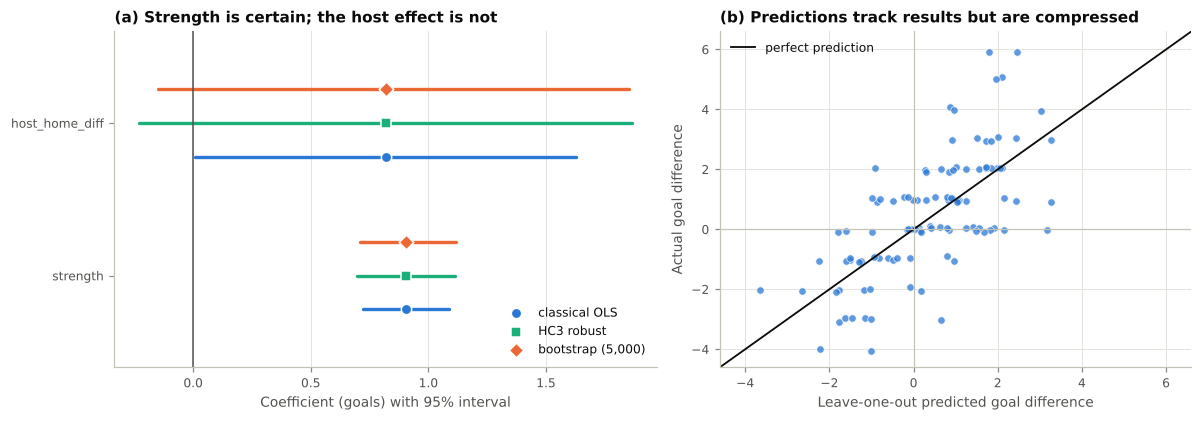

Range of predictions: -3.6 to 3.3; range of results: -4 to 6


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(11.0, 3.9), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
hc3_ci = final_hc3.conf_int()
intervals = {"classical OLS": (coef_tab.ci95_low, coef_tab.ci95_high, BLUE, "o"),
             "HC3 robust": (pd.Series(hc3_ci[:, 0], index=FINAL_COLS), pd.Series(hc3_ci[:, 1], index=FINAL_COLS), AQUA, "s"),
             "bootstrap (5,000)": (coef_tab.boot_ci_low, coef_tab.boot_ci_high, ORANGE, "D")}
for k, (lab, (lo, hi, colour, marker)) in enumerate(intervals.items()):
    for j, term in enumerate(FINAL_COLS):
        yy = j + (k - 1) * 0.22
        ax.plot([lo[term], hi[term]], [yy, yy], color=colour, lw=2.2, solid_capstyle="round")
        ax.scatter(final.params[term], yy, color=colour, marker=marker, s=46, edgecolor="white", linewidth=1, zorder=3,
                   label=lab if j == 0 else None)
ax.axvline(0, color=INK2, lw=1)
ax.set_yticks([0, 1]); ax.set_yticklabels(["strength", "host_home_diff"]); ax.set_ylim(-0.6, 1.6)
ax.set(xlabel="Coefficient (goals) with 95% interval", title="(a) Strength is certain; the host effect is not")
ax.grid(axis="y", visible=False); ax.legend(loc="lower right")

ax = axes[1]
lim = (-4.6, 6.6)
ax.plot(lim, lim, color=INK, lw=1.2, label="perfect prediction")
jit = np.random.default_rng(SEED)
ax.scatter(loo_pred, y + jit.uniform(-0.1, 0.1, n), s=24, color=BLUE, alpha=0.75, edgecolor="white", linewidth=0.6)
ax.axhline(0, color=AXIS, lw=0.8); ax.axvline(0, color=AXIS, lw=0.8)
ax.set(xlim=lim, ylim=lim, xlabel="Leave-one-out predicted goal difference", ylabel="Actual goal difference",
       title="(b) Predictions track results but are compressed")
ax.legend(loc="upper left")
fig.tight_layout()
savefig(fig, "fig10_coefficients_and_predictions")
print(f"Range of predictions: {loo_pred.min():.1f} to {loo_pred.max():.1f}; range of results: {y.min():.0f} to {y.max():.0f}")

Panel (a) puts the three kinds of interval side by side: all three agree on strength, and all three show how
little 13 matches can say about the host effect. Panel (b) shows a property every regression of a noisy
target has: predictions are pulled toward zero (about −3.6 to +3.3) while results run from −4 to +6. The
model gives the expected margin, and never forecasts a blow-out.

## 14. Sensitivity analyses

Three choices made upstream could in principle drive the result, so each is tested.

1. **Timing of the squad values.** Role 1's data dictionary flags that one source dates the Transfermarkt
   values 15 July 2026. The same figures appear in an article dated 18 June 2026 that credits "PlanetFootball,
   June 2026", so they were public by the first day of matchday 2 at the latest. Whether they pre-date the
   opening match on 11 June is not confirmed, so the 24 matchday-1 games (11–17 June) are the only ones that
   could be affected. We therefore refit on the 56 matches from matchday 3 onward (24 June and later), where
   the values were certainly known before kick-off, and we also fit a model that drops squad value entirely.
2. **Definition of the target.** The dataset counts goals after extra time. Five knockout matches were
   level after 90 minutes and decided in extra time; we refit with their 90-minute difference (zero).
3. **The host term.** We refit without it.

In [36]:
y90 = (meta.ft1 - meta.ft2).to_numpy(float)     # 90-minute goal difference from the OpenFootball metadata
et_rows = y90 != y                              # matches whose result changed in extra time
assert et_rows.sum() == 5 and (df.stage_ord[et_rows] >= 4).all()
late = (df.stage_ord >= 3).to_numpy()

def refit(cols, mask=None, target=y):
    mask = np.ones(n, bool) if mask is None else mask
    f = sm.OLS(target[mask], df.loc[mask, cols]).fit()
    return f

sens = []
for label, cols, mask, target in [
    ("Final model, all 104 matches", FINAL_COLS, None, y),
    ("Matchday 3 onward only (56 matches, squad values certainly pre-match)", FINAL_COLS, late, y),
    ("Target = 90-minute goal difference (5 matches change)", FINAL_COLS, None, y90),
    ("Without the host term", ["strength"], None, y),
    ("Without squad value: FIFA rank + host", ["log_rank_diff", "host_home_diff"], None, y),
]:
    f = refit(cols, mask, target)
    main = cols[0]
    sens.append(dict(check=label, n=int(f.nobs), main_term=main, coef=f.params[main], std_err=f.bse[main],
                     ci_low=f.conf_int().loc[main, 0], ci_high=f.conf_int().loc[main, 1],
                     host_coef=f.params.get("host_home_diff", np.nan), residual_sd=np.sqrt(f.mse_resid)))
sens_tab = pd.DataFrame(sens).set_index("check")
with pd.option_context("display.max_colwidth", 80):
    display(sens_tab)

rank_only = score("Symmetric OLS: rank + host (no squad value)", OLS0, ["log_rank_diff", "host_home_diff"], "sensitivity")
fallback = pd.DataFrame([rank_only]).set_index("model")[["cv_rmse", "cv_r2", "wf_rmse"]]
fallback.loc["Final model (for comparison)"] = board.loc[FINAL, ["cv_rmse", "cv_r2", "wf_rmse"]]
fallback.loc["Full OLS, 8 variables (for comparison)"] = board.loc[REFERENCE, ["cv_rmse", "cv_r2", "wf_rmse"]]
display(fallback)
# leave-one-team-out: the same teams appear in several matches, so drop each team's matches in turn and refit
loto = []
for team in sorted(set(df.team1) | set(df.team2)):
    keep_t = ((df.team1 != team) & (df.team2 != team)).to_numpy()
    f_t = sm.OLS(y[keep_t], df.loc[keep_t, FINAL_COLS]).fit()
    loto.append(dict(team_removed=team, matches_left=int(keep_t.sum()), strength=f_t.params["strength"], host=f_t.params["host_home_diff"]))
loto = pd.DataFrame(loto).set_index("team_removed")
print(f"Leave-one-team-out (48 refits): strength coefficient {loto.strength.min():.2f} to {loto.strength.max():.2f}; "
      f"host coefficient {loto.host.min():.2f} to {loto.host.max():.2f}")
display(pd.concat([loto.nsmallest(3, "host"), loto.nlargest(3, "host")]))
late_two = sm.OLS(y[late], df.loc[late, ["log_rank_diff", "log_value_diff"]]).fit()
print(f"Matchday 3 onward, rank and value entered separately: b_value = {late_two.params['log_value_diff']:.2f} "
      f"(p = {late_two.pvalues['log_value_diff']:.3f}); all matches: b_value = {two.params['log_value_diff']:.2f}")

,n,main_term,coef,std_err,ci_low,ci_high,host_coef,residual_sd
check,,,,,,,,
"Final model, all 104 matches",104,strength,0.905,0.091,0.723,1.086,0.818,1.464
"Matchday 3 onward only (56 matches, squad values certainly pre-match)",56,strength,0.873,0.115,0.642,1.103,0.262,1.280
Target = 90-minute goal difference (5 matches change),104,strength,0.870,0.093,0.685,1.054,0.831,1.490
Without the host term,104,strength,0.920,0.092,0.737,1.103,NaN,1.485
Without squad value: FIFA rank + host,104,log_rank_diff,0.812,0.095,0.624,1.001,0.807,1.564


,cv_rmse,cv_r2,wf_rmse
model,,,
Symmetric OLS: rank + host (no squad value),1.590,0.377,1.533
Final model (for comparison),1.489,0.453,1.433
"Full OLS, 8 variables (for comparison)",1.546,0.411,1.817


Leave-one-team-out (48 refits): strength coefficient 0.87 to 0.99; host coefficient 0.50 to 1.25


,matches_left,strength,host
team_removed,,,
Qatar,101,0.896,0.499
Mexico,99,0.905,0.534
Czech Republic,101,0.906,0.676
USA,99,0.888,1.254
Belgium,98,0.892,1.104
Turkey,101,0.919,0.965


Matchday 3 onward, rank and value entered separately: b_value = 0.48 (p = 0.017); all matches: b_value = 0.53


**Reading the sensitivity checks.**

* **Squad-value timing.** On the 56 matches where the values were certainly known in advance, the strength
  coefficient is 0.87 (95 % CI 0.64–1.10) against 0.90 on all matches, and squad value entered separately is
  still significant (0.48, p = 0.017). The conclusions do not depend on matchday 1. If squad value had to be
  dropped altogether, a rank-plus-host model would still beat the full OLS where it matters (walk-forward RMSE
  1.53 against 1.82), at a cost of about 0.10 goals of CV RMSE relative to the final model.
* **Target definition.** Using 90-minute scores changes five matches and moves the strength coefficient from
  0.90 to 0.87.
* **Host term.** Removing it changes the strength coefficient by 0.02. The host coefficient itself is not
  stable: 0.82 on all matches but 0.26 on the later subset, which contains only 7 host matches. This confirms
  the caution in Section 11: the sign agrees with theory, the size cannot be pinned down from this tournament.

* **Repeated teams.** Each team appears in several matches, so we dropped every team's matches in turn (48
  refits). The strength coefficient stays between 0.87 and 0.99. The host coefficient ranges from 0.50 (without
  Qatar) to 1.25 (without the USA): it depends on a handful of matches.

The strength effect, which carries the model, stays between 0.87 and 0.99 in every check.

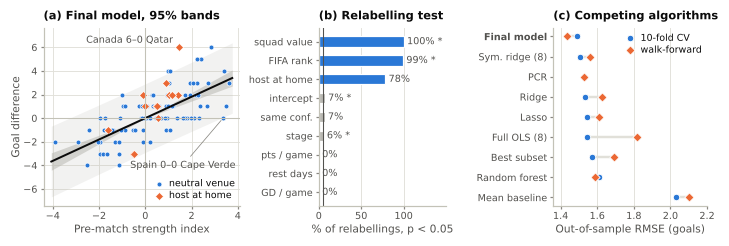

In [37]:
# ------------------------------------------------------------------ composite figure for the 4-page report
fig = plt.figure(figsize=(6.5, 2.3))                            # 16.5 cm wide: fits an A4 text column
ax_a = fig.add_axes([0.062, 0.19, 0.275, 0.70])
ax_b = fig.add_axes([0.447, 0.19, 0.178, 0.70])
ax_c = fig.add_axes([0.775, 0.19, 0.215, 0.70])
small = dict(fontsize=6.3, color=INK2)

ax = ax_a
ax.fill_between(gx, band.obs_ci_lower, band.obs_ci_upper, color=GREY, alpha=0.18, lw=0)
ax.fill_between(gx, band.mean_ci_lower, band.mean_ci_upper, color=GREY, alpha=0.55, lw=0)
ax.plot(gx, band["mean"], color=INK, lw=1.3)
ax.axhline(0, color=AXIS, lw=0.7); ax.axvline(0, color=AXIS, lw=0.7)
ax.scatter(df.strength[~host], y[~host], s=10, color=BLUE, edgecolor="white", linewidth=0.45, label="neutral venue")
ax.scatter(df.strength[host], y[host], s=14, marker="D", color=ORANGE, edgecolor="white", linewidth=0.45, label="host at home")
r = df.loc[df.match_id == 28].iloc[0]
ax.annotate(r.label, (r.strength, r.goal_diff), xytext=(-4, 3), textcoords="offset points", ha="right", **small)
r = df.loc[df.match_id == 15].iloc[0]
ax.annotate(r.label, (r.strength, r.goal_diff), xytext=(3.9, -4.0), textcoords="data", ha="right", va="center",
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.5, shrinkA=1, shrinkB=2), **small)
ax.set_xlim(-4.4, 4.1); ax.set_ylim(-7.4, 7.6)
ax.set_xlabel("Pre-match strength index", fontsize=7, labelpad=2); ax.set_ylabel("Goal difference", fontsize=7, labelpad=1)
ax.set_title("(a) Final model, 95% bands", fontsize=7.5)
ax.legend(loc="lower right", fontsize=6.2, handletextpad=0.1, borderaxespad=0.15, labelspacing=0.25)

ax = ax_b
nick = {"log_value_diff": "squad value", "log_rank_diff": "FIFA rank", "host_home_diff": "host at home",
        "intercept": "intercept", "same_confed": "same conf.", "stage_ord": "stage", "ppg_diff": "pts / game",
        "rest_days_diff": "rest days", "gd_pg_diff": "GD / game"}
o2 = flip_tab.sort_values("share_significant_relabelled").index
sh2 = flip_tab.loc[o2, "share_significant_relabelled"] * 100
yp = np.arange(len(o2))
ax.barh(yp, sh2, height=0.55, color=np.where(sh2 > 50, BLUE, GREY), edgecolor="white", linewidth=0.8)
ax.axvline(5, color=INK2, lw=0.7)
for yi, (v, sig) in enumerate(zip(sh2, flip_tab.loc[o2, "p_as_scheduled"] < 0.05)):
    ax.text(v + 4, yi, f"{v:.0f}%" + (" *" if sig else ""), va="center", **small)
ax.set_yticks(yp); ax.set_yticklabels([nick[i] for i in o2], fontsize=6.3)
ax.set_xlim(0, 150); ax.set_xticks([0, 50, 100])
ax.set_xlabel("% of relabellings, p < 0.05", fontsize=7, labelpad=2)
ax.set_title("(b) Relabelling test", fontsize=7.5)
ax.grid(axis="y", visible=False)

ax = ax_c
picks = ["Baseline: training mean", "Random forest", REFERENCE, "Best subset (nested selection)", "Ridge", "Lasso",
         "Principal-component regression", "Symmetric ridge: all 8 variables", FINAL]
short = {"Baseline: training mean": "Mean baseline", REFERENCE: "Full OLS (8)", "Best subset (nested selection)": "Best subset",
         "Principal-component regression": "PCR", "Symmetric ridge: all 8 variables": "Sym. ridge (8)", FINAL: "Final model"}
sub = board.loc[picks].sort_values("cv_rmse", ascending=False)
yp = np.arange(len(sub))
ax.hlines(yp, sub[["cv_rmse", "wf_rmse"]].min(axis=1), sub[["cv_rmse", "wf_rmse"]].max(axis=1), color=GRID, lw=1.6, zorder=1)
ax.scatter(sub.cv_rmse, yp, s=18, color=BLUE, edgecolor="white", linewidth=0.6, zorder=3, label="10-fold CV")
ax.scatter(sub.wf_rmse, yp, s=18, marker="D", color=ORANGE, edgecolor="white", linewidth=0.6, zorder=3, label="walk-forward")
ax.set_yticks(yp); ax.set_yticklabels([short.get(i, i) for i in sub.index], fontsize=6.3)
ax.get_yticklabels()[-1].set_fontweight("bold")
ax.set_xlim(1.36, 2.2); ax.set_xticks([1.4, 1.6, 1.8, 2.0, 2.2])
ax.set_xlabel("Out-of-sample RMSE (goals)", fontsize=7, labelpad=2)
ax.set_title("(c) Competing algorithms", fontsize=7.5)
ax.grid(axis="y", visible=False)
ax.legend(loc="upper right", fontsize=6.2, handletextpad=0.1, borderaxespad=0.15, labelspacing=0.25)
for a in fig.axes:
    a.tick_params(labelsize=6.3, length=2, pad=2)
fig.savefig(FIG / "report_figure_LR21.png", dpi=400, bbox_inches=None)
plt.show()

In [38]:
# ------------------------------------------------------------------ compact table for the 4-page report
report_models = ["Baseline: training mean", "Simple OLS: log_rank_diff", REFERENCE, "Ridge", "Lasso", "Random forest",
                 "Symmetric OLS: strength (E3)", FINAL]
report_tab = board.loc[report_models, ["n_terms", "cv_rmse", "cv_mae", "cv_r2", "wf_rmse"]].copy()
report_tab.loc[["Baseline: training mean"], "n_terms"] = 0
report_tab.columns = ["Terms", "CV RMSE", "CV MAE", "CV R2", "Walk-forward RMSE"]
display(report_tab.round(3))
report_tab.round(3).to_csv(RES / "lr21_report_table.csv")

key = {
    "n": n, "cv_rmse_full": board.loc[REFERENCE, "cv_rmse"], "cv_rmse_final": board.loc[FINAL, "cv_rmse"],
    "wf_rmse_full": board.loc[REFERENCE, "wf_rmse"], "wf_rmse_final": board.loc[FINAL, "wf_rmse"],
    "cv_r2_full": board.loc[REFERENCE, "cv_r2"], "cv_r2_final": board.loc[FINAL, "cv_r2"],
    "cv_gain_pct": board.loc[FINAL, "cv_gain_vs_full_ols_%"], "wf_gain_pct": board.loc[FINAL, "wf_gain_vs_full_ols_%"],
    "b_strength": final.params["strength"], "b_host": final.params["host_home_diff"],
    "sigma": sigma, "r2_centered": r2_centered, "loo_winner_acc": practical.iloc[5], "pi_coverage": practical.iloc[7],
}
pd.Series(key, name="value").to_csv(RES / "lr21_key_numbers.csv")
display(pd.Series(key, name="value").to_frame())

,Terms,CV RMSE,CV MAE,CV R2,Walk-forward RMSE
model,,,,,
Baseline: training mean,0,2.033,1.591,-0.019,2.101
Simple OLS: log_rank_diff,1,1.599,1.235,0.370,1.553
Full OLS: all 8 variables,8,1.546,1.226,0.411,1.817
Ridge,8,1.535,1.191,0.419,1.625
Lasso,8,1.544,1.204,0.412,1.609
Random forest,8,1.607,1.278,0.363,1.585
Symmetric OLS: strength (E3),1,1.497,1.163,0.448,1.438
Symmetric OLS: strength + host (E4),2,1.489,1.150,0.453,1.433


,value
n,104.000
cv_rmse_full,1.546
cv_rmse_final,1.489
wf_rmse_full,1.817
wf_rmse_final,1.433
cv_r2_full,0.411
cv_r2_final,0.453
cv_gain_pct,3.656
wf_gain_pct,21.143
b_strength,0.905


## 15. Conclusions and recommendations

**Model.** `goal_diff = 0.90 × strength + 0.82 × host_home_diff`, with no intercept, where
`strength = ½ (log_rank_diff + log_value_diff)`. `strength` combines two of the eight original variables with equal weights; it is not a
ninth variable, so the model uses three of the eight (`log_rank_diff`, `log_value_diff`, `host_home_diff`).

**What we learned about the eight variables**

| Variable | Verdict | Evidence |
|---|---|---|
| `log_rank_diff`, `log_value_diff` | **Keep, merged into one index** | r = 0.63 / 0.66 alone, 0.68 combined; equal weights not rejected; present in every top subset |
| `host_home_diff` | **Keep, with caution** | Lowers both validation errors; +0.8 goals, but only 13 informative matches |
| `ppg_diff`, `gd_pg_diff` | Drop | Partial r ≈ −0.06 once strength is known: form is strength in disguise |
| `rest_days_diff` | Drop | No association (r = −0.05); 80 % of matches have identical rest |
| `stage_ord` | Drop | Its "significance" is a listing-order artefact (relabelling test); no effect on the size of the margin either |
| `same_confed` | Drop | No effect on the signed margin; in practice a "Europe v Europe" flag (12 matches); exploratory interaction not robust |

**How the model was improved** (out-of-sample RMSE in goals; the table is generated in the next cell)


In [39]:
steps = {"Mean baseline": "Baseline: training mean", "Full OLS, 8 variables": REFERENCE,
         "Ridge on the same 8 variables": "Ridge", "Strength index, symmetric": "Symmetric OLS: strength (E3)",
         "Final: strength + host, symmetric": FINAL}
improve = pd.DataFrame({"CV RMSE": [board.loc[v, "cv_rmse"] for v in steps.values()],
                        "CV R2": [board.loc[v, "cv_r2"] for v in steps.values()],
                        "Walk-forward RMSE": [board.loc[v, "wf_rmse"] for v in steps.values()]}, index=list(steps))
improve["CV RMSE vs full OLS"] = (improve["CV RMSE"] / improve.loc["Full OLS, 8 variables", "CV RMSE"] - 1).map("{:+.1%}".format)
improve["Walk-forward vs full OLS"] = (improve["Walk-forward RMSE"] / improve.loc["Full OLS, 8 variables", "Walk-forward RMSE"] - 1).map("{:+.1%}".format)
display(improve)

,CV RMSE,CV R2,Walk-forward RMSE,CV RMSE vs full OLS,Walk-forward vs full OLS
Mean baseline,2.033,-0.019,2.101,+31.5%,+15.6%
"Full OLS, 8 variables",1.546,0.411,1.817,+0.0%,+0.0%
Ridge on the same 8 variables,1.535,0.419,1.625,-0.7%,-10.6%
"Strength index, symmetric",1.497,0.448,1.438,-3.2%,-20.9%
"Final: strength + host, symmetric",1.489,0.453,1.433,-3.7%,-21.1%


**Recommendations**

1. **Use the symmetric two-term OLS** for prediction. It is the most accurate model on both validation
   schemes, the simplest, and the only family that is unaffected by which team is listed first.
   The strength-only version is interchangeable with it. If every one of the eight variables must appear in
   the final equation, use the weighted symmetric ridge (CV 1.51, walk-forward 1.45, hold-out 1.52): with
   its tuning done forward in time it matched the final model on the last 16 matches.
2. **Validate chronologically as well as randomly.** Random CV alone rated the full OLS as nearly as good
   as the final model; only walk-forward validation exposed its 27 % higher error on future matches.
3. **Quote predictions with their interval** (about ±2.9 goals). Pre-match information explains a little
   under half of the variance in goal difference; the remainder is what happens on the pitch.
4. **For the group's variable list:** the two form variables are redundant with each other and with
   strength, and `rest_days_diff` barely varies. If the group revises the dataset, those three slots are the
   ones to reconsider; the model above does not depend on them.

**Limitations.** One tournament and 104 matches: the host effect in particular rests on 13 matches.
The squad values are confirmed public only from 18 June; Section 14 shows the conclusions do not depend on it.
FIFA rank and squad value are imperfect, slowly updated measures of strength. Goal difference is a discrete
quantity modelled here as continuous, which the residual diagnostics show to be an acceptable approximation.
Results after extra time are counted and penalty shoot-outs are not, as defined by the group's data dictionary.

In [40]:
# ------------------------------------------------------------------ every number quoted on the report page
pc_form = pd.DataFrame(pc_rows).set_index("variable")
robust_vals = [robust_tab.iloc[:, 1]["strength"], sens_tab.loc["Matchday 3 onward only (56 matches, squad values certainly pre-match)", "coef"],
               sens_tab.loc["Target = 90-minute goal difference (5 matches change)", "coef"], loto.strength.min(), loto.strength.max()]
report_numbers = {
    "n_matches": n, "n_matchday1": int((df.stage_ord == 1).sum()),
    "mean_gd": float(y.mean()), "sd_gd": float(y.std(ddof=1)), "p_mean_zero": float(t_mean.pvalue),
    "r_rank": float(corr_tab.loc["log_rank_diff", "pearson_r"]), "r_value": float(corr_tab.loc["log_value_diff", "pearson_r"]),
    "r_rank_value": float(df.log_rank_diff.corr(df.log_value_diff)),
    "r_form": float(corr_tab.loc[["ppg_diff", "gd_pg_diff"], "pearson_r"].mean()),
    "partial_form": float(pc_form.loc[["ppg_diff", "gd_pg_diff"], "partial_r_given_strength"].mean()),
    "partial_form_p_min": float(pc_form.loc[["ppg_diff", "gd_pg_diff"], "partial_p"].min()),
    "p_intercept": float(ols8.pvalues["const"]), "p_stage": float(ols8.pvalues["stage_ord"]),
    "flip_share_intercept": float(flip_tab.loc["intercept", "share_significant_relabelled"]),
    "flip_share_stage": float(flip_tab.loc["stage_ord", "share_significant_relabelled"]),
    "flip_share_rank": float(flip_tab.loc["log_rank_diff", "share_significant_relabelled"]),
    "flip_share_value": float(flip_tab.loc["log_value_diff", "share_significant_relabelled"]),
    "mirror_gap_mean": float(gap_full.mean()), "mirror_gap_max": float(gap_full.max()),
    "cv_repeats": N_REPEATS, "wf_forecasts": int(wf_mask.sum()),
    "adj_r2_full": float(ols8.rsquared_adj), "cv_full": float(board.loc[REFERENCE, "cv_rmse"]),
    "wf_full": float(board.loc[REFERENCE, "wf_rmse"]), "wf_rank_only": float(board.loc["Simple OLS: log_rank_diff", "wf_rmse"]),
    "p_equal_weights": float(np.asarray(eq.pvalue).item()), "n_models": int(len(board)),
    "b_strength": float(final.params["strength"]), "b_host": float(final.params["host_home_diff"]),
    "cv_final": float(board.loc[FINAL, "cv_rmse"]), "wf_final": float(board.loc[FINAL, "wf_rmse"]),
    "cv_gain_pct": float(board.loc[FINAL, "cv_gain_vs_full_ols_%"]), "wf_gain_pct": float(board.loc[FINAL, "wf_gain_vs_full_ols_%"]),
    "wf_diff_ci_low": float(cmp_tab.loc[REFERENCE, "wf_ci_low"]), "wf_diff_ci_high": float(cmp_tab.loc[REFERENCE, "wf_ci_high"]),
    "doubling_effect": float(final.params["strength"] * np.log(2)),
    "ci_strength_low": float(coef_tab.loc["strength", "ci95_low"]), "ci_strength_high": float(coef_tab.loc["strength", "ci95_high"]),
    "robust_low": float(min(robust_vals)), "robust_high": float(max(robust_vals)),
    "n_host_matches": int((df.host_home_diff != 0).sum()), "p_host_hc3": float(coef_tab.loc["host_home_diff", "p_HC3_robust"]),
    "p_host_cluster": float(coef_tab.loc["host_home_diff", "p_date_cluster"]),
    "p_shapiro": float(diag_tests.set_index("test").loc["Shapiro-Wilk", "p_value"]),
    "p_bp": float(diag_tests.set_index("test").loc["Breusch-Pagan", "p_value"]),
    "p_reset": float(diag_tests.set_index("test").loc["Ramsey RESET (powers 2-3)", "p_value"]),
    "hold_draw": float(date_tab.loc["Baseline: always a draw", "holdout_rmse"]),
    "hold_final": float(date_tab.loc[FINAL, "holdout_rmse"]), "hold_strength_only": float(date_tab.loc["Symmetric OLS: strength (E3)", "holdout_rmse"]),
    "pi_half_width": float(practical.iloc[8]), "pi_coverage": float(practical.iloc[7]),
}
pd.Series(report_numbers).to_json(RES / "lr21_report_numbers.json", indent=1)
display(pd.Series(report_numbers).to_frame("value"))

,value
n_matches,104.000
n_matchday1,24.000
mean_gd,0.481
sd_gd,2.024
p_mean_zero,0.017
r_rank,0.629
r_value,0.662
r_rank_value,0.786
r_form,0.319
partial_form,-0.057
